# Next April
**VoltRelay Energy: what drives service failures, rider churn and margins, and what to fix before summer 2026**

Dhiraj Kavuri · Gradient Learnings Data Analytics Hackathon · 15 Nov 2026

This notebook runs top to bottom from the organiser's eight CSV files. Every number used in the report, the video and the summary is computed here and written to `outputs/facts.json`; a separate check fails if any text quotes a number that is not in that file.

**The answer.** The same old Gen1 cabinets in Jaipur, Delhi NCR and Hyderabad fail every summer: they overheat, charge slowly and run out of charged packs. A rule built from summer 2024 alone predicted summer 2025 (section 10), and the new stations opened in between did not reach them. An empty shelf is a symptom, not the cause: at the same station and temperature, cabinets showing charged packs turn riders away just as often (section 5). So fix those 36 cabinets instead of adding stations or stocking more packs, and replace the Kyron battery fleet (section 11).

**Contents.** 1 Data understanding · 2 Data cleaning (every issue, rows, effect) · 3-8 the six core questions · 9 What the failures cost · 10 The back-test, the April 2026 list, expansion waves, anomalies · 11 Budget verdicts and a pack-buffer test · 12 Self-audit · 13 AI use

## Setup
Downloads the dataset from the organiser's shared Drive folder if it is not already present. On Colab this takes about two minutes (the swap table is 729 MB).

In [1]:
import os, sys, json, subprocess, warnings
warnings.filterwarnings("ignore")

def _need(pkg, mod=None):
    try:
        __import__(mod or pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

for p, m in [("duckdb", None), ("gdown", None), ("statsmodels", None), ("pyarrow", None)]:
    _need(p, m)

import duckdb, gdown
import numpy as np, pandas as pd
import pyarrow.csv as pacsv, pyarrow.parquet as pq
import matplotlib
matplotlib.use("Agg") if not hasattr(sys, "ps1") and "ipykernel" not in sys.modules else None
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

ROOT = os.environ.get("NA_ROOT", ".")
RAW = os.path.join(ROOT, "data", "raw")
PQ = os.path.join(ROOT, "data", "pq")
OUT = os.path.join(ROOT, "outputs")
CH = os.path.join(OUT, "charts")
for d in (RAW, PQ, OUT, CH):
    os.makedirs(d, exist_ok=True)

# The organiser's Drive folder: https://drive.google.com/drive/folders/1qsjGWrgmEvOaf2Is2fh7RgVEkKd1V3df
FILES = {
    "batteries": "1ODkUSlw3EzpzznYdzZe74wG84t3783al",
    "city_daily_context": "1UMDldAGOUEJitZ32D4M9szwRMvUjZc4G",
    "fleet_partners": "1fMy7LxZxESBqeveFB3iabpE3sxjnkkmY",
    "riders": "1w3TxH3NY2rk_agikJtv3oCq2OeXv1Pii",
    "station_hourly_status": "1pbGACXY95BemIbrSlRxE6o8CGcc2bSCn",
    "stations": "1WEou9h5lYvALA3IreUFoCRbmIh2_9Dm2",
    "support_tickets": "1tWK-zDoRy8QFqQe9ESw8ttpKHqMqMXbh",
    "swap_events": "15qkHruvAilomjWdNgntXrQLK4-_NPOZZ",
}
EXPECTED_ROWS = {"swap_events": 3877013, "station_hourly_status": 1487712, "riders": 20000,
                 "batteries": 6500, "support_tickets": 44000, "stations": 152,
                 "city_daily_context": 3282, "fleet_partners": 12}

import time, urllib.request

def fetch(fid, dest, tries=5):
    """Download one file from the organiser's Drive folder; retry, then fall back to the direct download URL."""
    for i in range(tries):
        try:
            if i < 3:
                gdown.download(id=fid, output=dest, quiet=True)
            else:
                urllib.request.urlretrieve(f"https://drive.usercontent.google.com/download?id={fid}&export=download&confirm=t", dest)
            with open(dest, "rb") as f:
                head = f.read(200)
            if b"," in head and b"<html" not in head.lower():
                return
        except Exception as err:
            print(f"download attempt {i+1} for {os.path.basename(dest)} failed: {err}")
        time.sleep(3*(i+1))
    raise RuntimeError(f"Could not download {dest}; download it from the organiser's Drive folder into {RAW} and re-run")

for name, fid in FILES.items():
    csv = os.path.join(RAW, f"{name}.csv")
    if not os.path.exists(csv):
        fetch(fid, csv)
    out = os.path.join(PQ, f"{name}.parquet")
    if not os.path.exists(out):
        # Empty strings in ID columns mean "missing": read them as nulls.
        t = pacsv.read_csv(csv, convert_options=pacsv.ConvertOptions(
            strings_can_be_null=True, null_values=[""],
            timestamp_parsers=["%Y-%m-%d %H:%M:%S", "%Y-%m-%d"]))
        pq.write_table(t, out)

con = duckdb.connect()
for name in FILES:
    con.execute(f"create or replace view raw_{name} as select * from '{PQ}/{name}.parquet'")

def sql(q):
    return con.sql(q).df()

rowcheck = pd.DataFrame([(n, int(sql(f"select count(*) c from raw_{n}").c[0]), r) for n, r in EXPECTED_ROWS.items()],
                        columns=["table", "rows", "expected"])
assert (rowcheck.rows == rowcheck.expected).all(), rowcheck
print(rowcheck.to_string(index=False))

                table    rows  expected
          swap_events 3877013   3877013
station_hourly_status 1487712   1487712
               riders   20000     20000
            batteries    6500      6500
      support_tickets   44000     44000
             stations     152       152
   city_daily_context    3282      3282
       fleet_partners      12        12


In [2]:
FACTS = {}
def fact(key, value, nd=None):
    """Record a number used anywhere in the write-up. Returns it rounded for display."""
    v = float(value)
    FACTS[key] = v
    return round(v, nd) if nd is not None else v

def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(CH, f"{name}.png"), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 11})
INK, ACCENT, MUTED, GOOD = "#222222", "#c0392b", "#9aa0a6", "#1f6f8b"

## 1. Data understanding
Eight linked tables. The core fact table has **one row per swap attempt**, completed or not, so a failure rate is non-completed attempts divided by all attempts. Five things changed during the 18 months, and each needs to be separated from the others: two station expansion waves, a base price change, a peak/off-peak pricing pilot in two cities, a new battery supplier (Kyron) and a renegotiated contract with the largest fleet partner (ZipDrop).

In [3]:
grain = pd.DataFrame([
    ("swap_events", "one swap attempt", "event_id"),
    ("station_hourly_status", "one station-hour of cabinet telemetry", "station_id + hour_start"),
    ("riders", "one registered rider", "rider_id"),
    ("batteries", "one battery pack", "battery_id"),
    ("support_tickets", "one support ticket", "ticket_id"),
    ("stations", "one swap station", "station_id"),
    ("city_daily_context", "one city-day of weather and calendar", "city + date"),
    ("fleet_partners", "one B2B fleet customer contract", "partner_id"),
], columns=["table", "one row is", "key"])
print(grain.to_string(index=False))
print()
print(sql("select event_type, count(*) attempts, round(100.0*count(*)/sum(count(*)) over (),2) pct from raw_swap_events group by 1 order by 2 desc").to_string(index=False))
fact("attempts_all", sql("select count(*) c from raw_swap_events").c[0])
fact("completion_pct_all", 100*sql("select avg((event_type='swap_completed')::int) c from raw_swap_events").c[0])
print(sql("select partner_id, partner_name, partner_segment, contract_type, discount_pct, amendment_date, discount_pct_after_amendment, peak_surcharge_billable from raw_fleet_partners").to_string(index=False))

                table                            one row is                     key
          swap_events                      one swap attempt                event_id
station_hourly_status one station-hour of cabinet telemetry station_id + hour_start
               riders                  one registered rider                rider_id
            batteries                      one battery pack              battery_id
      support_tickets                    one support ticket               ticket_id
             stations                      one swap station              station_id
   city_daily_context  one city-day of weather and calendar             city + date
       fleet_partners       one B2B fleet customer contract              partner_id

               event_type  attempts   pct
           swap_completed   3645809 94.04
failed_no_charged_battery    134389  3.47
          abandoned_queue     68533  1.77
       cancelled_by_rider     16712  0.43
      failed_system_error     115

## 2. Data cleaning: every issue, how many rows, what we did, and what it changes
The organiser documented nine data quality issues. We checked each one and looked for others. Each row of the table below says how many records are affected, the decision taken, and the effect on a number used later.

In [4]:
issues = []
def issue(name, documented, rows, decision, effect):
    issues.append(dict(issue=name, documented=documented, rows_affected=rows, decision=decision, effect=effect))

# 2.1 Test stations
t = sql("select count(*) n, sum(amount_charged_inr) amt, count(distinct station_id) st from raw_swap_events where station_id like 'STN-TST%'")
fact("test_rows", t.n[0]); fact("test_amount_inr", t.amt[0]); fact("test_amount_lakh", t.amt[0]/1e5)
th = sql("select hour(event_ts) h, count(*) n from raw_swap_events where station_id like 'STN-TST%' group by 1 order by 2 desc limit 1")
issue("Test stations STN-TST-01/02", "yes, as 'a small number of zero-value transactions at unusual hours'",
      int(t.n[0]), "Excluded from all network analysis",
      f"Docs understate it: {int(t.n[0]):,} rows charging ₹{t.amt[0]/1e5:.1f} lakh, busiest at {int(th.h[0])}:00, not zero-value. Keeping them would add ₹{t.amt[0]/1e5:.1f} lakh of revenue that never happened.")

# 2.2 Firmware clock bug
fw = sql("""select count(*) n from raw_swap_events where station_firmware='v3.2.0'
            and event_ts >= '2025-03-10' and event_ts < '2025-04-15'""").n[0]
fact("firmware_rows", fw)
night = sql("""select
  avg((hour(event_ts) between 0 and 4)::int) filter (where station_firmware='v3.2.0' and event_ts >= '2025-03-10' and event_ts < '2025-04-15') bug,
  avg((hour(event_ts) between 0 and 4)::int) filter (where not (station_firmware='v3.2.0' and event_ts >= '2025-03-10' and event_ts < '2025-04-15')) rest
  from raw_swap_events""")
night_fixed = sql("""select avg((hour(event_ts + interval 330 minute) between 0 and 4)::int) v from raw_swap_events
  where station_firmware='v3.2.0' and event_ts >= '2025-03-10' and event_ts < '2025-04-15'""").v[0]
fact("night_share_bug_pct", 100*night.bug[0]); fact("night_share_rest_pct", 100*night.rest[0]); fact("night_share_fixed_pct", 100*night_fixed)
issue("Firmware v3.2.0 clock 5h30 early (10 Mar-14 Apr 2025)", "yes", int(fw),
      "Added 5h30 to those timestamps",
      f"Share of these swaps logged between midnight and 5 AM falls from {100*night.bug[0]:.1f}% to {100*night_fixed:.1f}% (rest of data: {100*night.rest[0]:.1f}%), so hour-of-day results are right.")

# 2.3 Near-duplicates from offline sync
dups = {}
for label, key in [("rider+station+returned pack", "rider_id, station_id, battery_in_id"),
                   ("rider+station+issued pack", "rider_id, station_id, battery_out_id"),
                   ("rider+station, same outcome", "rider_id, station_id, event_type")]:
    dups[label] = int(sql(f"""with x as (select sync_mode, event_ts - lag(event_ts) over (partition by {key} order by event_ts) gap
                                         from raw_swap_events) select count(*) n from x where gap <= interval 3 minute""").n[0])
fact("dup_rows_strict", dups["rider+station+returned pack"])
fact("offline_rows", sql("select count(*) n from raw_swap_events where sync_mode='offline_batch'").n[0])
issue("Offline-sync near-duplicates", "yes", dups["rider+station+returned pack"],
      "Searched three ways within 3 minutes; nothing to remove",
      "Matches by key: " + "; ".join(f"{k}: {v:,}" for k, v in dups.items()) +
      f". The {int(FACTS['offline_rows']):,} offline_batch rows are not duplicates in this export, so all are kept.")

# 2.4 Non-completed attempts
nc = sql("select count(*) n from raw_swap_events where event_type<>'swap_completed'").n[0]
nc_amt = sql("select sum(amount_charged_inr) a from raw_swap_events where event_type<>'swap_completed'").a[0]
issue("Non-completed attempts", "yes", int(nc), "Kept for service and churn analysis; excluded from revenue, energy and range",
      f"They carry ₹{(nc_amt or 0):,.0f} of charges, so revenue is unaffected; leaving them out of failure rates would hide every failure.")

# 2.5 km and SOC outliers
o = sql("""select sum((km_since_last_swap<0)::int) neg, sum((km_since_last_swap>300)::int) big,
           sum((soc_out_pct>100)::int) soc, sum((soc_in_pct>100)::int) socin from raw_swap_events""")
fact("km_negative", o.neg[0]); fact("km_over300", o.big[0]); fact("soc_over100", o.soc[0])
med_raw = sql("select avg(km_since_last_swap) v from raw_swap_events where event_type='swap_completed'").v[0]
med_cln = sql("select avg(km_since_last_swap) v from raw_swap_events where event_type='swap_completed' and km_since_last_swap between 0 and 300").v[0]
issue("km_since_last_swap negative or > 300 km", "yes", int(o.neg[0] + o.big[0]),
      "Set to missing (odometer resets)", f"Mean km per swap moves from {med_raw:.1f} to {med_cln:.1f}.")
issue("soc_out_pct above 100", "yes", int(o.soc[0]), "Capped at 100 (sensor drift)", "Affects delivered-charge averages by less than 0.1 point.")

# 2.6 City spellings
cities = sql("select home_city, count(*) n from raw_riders group by 1 order by 2 desc")
CITY_MAP = {}
canon = {"bengaluru": "Bengaluru", "bangalore": "Bengaluru", "blr": "Bengaluru",
         "delhi ncr": "Delhi NCR", "delhi": "Delhi NCR", "new delhi": "Delhi NCR", "gurgaon": "Delhi NCR", "gurugram": "Delhi NCR", "noida": "Delhi NCR", "del": "Delhi NCR", "ncr": "Delhi NCR",
         "hyderabad": "Hyderabad", "hyd": "Hyderabad", "pune": "Pune", "pun": "Pune", "poona": "Pune",
         "mumbai": "Mumbai", "bombay": "Mumbai", "mum": "Mumbai", "bom": "Mumbai", "jaipur": "Jaipur", "jai": "Jaipur", "jpr": "Jaipur"}
for c in cities.home_city:
    k = str(c).strip().lower().replace(".", "")
    CITY_MAP[c] = canon.get(k)
unmapped = [c for c, v in CITY_MAP.items() if v is None]
assert not unmapped, f"unmapped city spellings: {unmapped}"
n_variant = int(cities[~cities.home_city.isin(["Bengaluru", "Delhi NCR", "Hyderabad", "Pune", "Mumbai", "Jaipur"])].n.sum())
fact("city_spellings", len(cities)); fact("city_variant_riders", n_variant)
issue("riders.home_city spellings", "yes", n_variant, f"Mapped {len(cities)} spellings to 6 cities",
      f"{n_variant} riders would otherwise sit in {len(cities)-6} phantom cities.")

# 2.7 Telemetry gaps
tel = sql("select telemetry_status, count(*) n from raw_station_hourly_status group by 1")
bad = int(tel[tel.telemetry_status != "ok"].n.sum())
fact("telemetry_bad_rows", bad)
poor_share = sql("""select avg((h.telemetry_status<>'ok')::int) filter (where s.connectivity_tier='poor') p,
                           avg((h.telemetry_status<>'ok')::int) filter (where s.connectivity_tier<>'poor') o
                    from raw_station_hourly_status h join raw_stations s using(station_id)""")
issue("Telemetry partial or missing", "yes", bad, "Those station-hours left out of telemetry averages, never treated as zero",
      f"Gaps hit {100*poor_share.p[0]:.1f}% of hours at poor-connectivity stations vs {100*poor_share.o[0]:.1f}% elsewhere.")

# 2.8 CSAT not missing at random
cs = sql("""select case when resolution_hours<4 then 'a <4h' when resolution_hours<24 then 'b 4-24h' else 'c >24h' end bucket,
            count(*) n, avg((csat_score is not null)::int) has, avg(csat_score) csat
            from raw_support_tickets where resolution_status='resolved' group by 1 order by 1""")
naive = sql("select avg(csat_score) v from raw_support_tickets").v[0]
w = (cs.n * cs.csat).sum() / cs.n.sum()
fact("csat_naive", naive); fact("csat_reweighted", w)
fact("csat_missing", sql("select count(*) n from raw_support_tickets where csat_score is null").n[0])
issue("CSAT mostly missing, not at random", "yes", int(FACTS["csat_missing"]),
      "Re-weighted CSAT by resolution-time bucket",
      f"Scores recorded on {100*cs.has.iloc[0]:.0f}% of <4h tickets vs {100*cs.has.iloc[-1]:.0f}% of >24h ones, but scores barely differ by resolution time ({', '.join(f'{v:.2f}' for v in cs.csat)}), so naive {naive:.2f} vs re-weighted {w:.2f}: the bias is real but small here.")

# 2.9 Ticket categories
VEHICLE_BLAME = ["general issue with the vehicle performance", "bike problem lag raha hai overall", "scooter weak lag raha hai aajkal"]
n_retag = int(sql("select count(*) n from raw_support_tickets where category='other' and rider_comment in ('" + "','".join(VEHICLE_BLAME) + "')").n[0])
n_other = int(sql("select count(*) n from raw_support_tickets where category='other'").n[0])
fact("tickets_retagged", n_retag); fact("tickets_other_total", n_other)
issue("Ticket category not verified", "yes", n_retag,
      "Re-tagged 'other' tickets whose comment blames the vehicle ('scooter weak', 'bike problem', 'vehicle performance') as battery/range complaints",
      f"All {n_other:,} 'other' tickets carry one of these three comments; section 6 shows they name Kyron packs as often as low-range tickets do, so battery complaints are undercounted by that much.")

# Undocumented issues we found
pm = sql("select payment_mode, count(*) n from raw_swap_events group by 1")
issue("payment_mode is the same on every row", "no (docs list upi / wallet / prepaid / partner_invoice)", int(pm.n.sum()),
      "Not used", f"All {int(pm.n.sum()):,} rows say '{pm.payment_mode[0]}', including independent riders, so payment channel cannot be analysed.")
bin_missing = sql("select count(*) n from raw_swap_events where battery_in_id is null").n[0]
issue("battery_in_id rarely missing", "no (docs: 'often missing')", int(bin_missing),
      "Read as null where blank", f"Only {int(bin_missing):,} blanks, and failed attempts still record a returned pack.")
early = sql("""select count(*) n, median(date_diff('day', e.event_ts, b.commission_date)) d
               from raw_swap_events e join raw_batteries b on b.battery_id=e.battery_out_id where e.event_ts < b.commission_date""")
fact("batt_before_commission_rows", early.n[0]); fact("batt_before_commission_median_days", early.d[0])
issue("Packs issued before their commission_date", "no", int(early.n[0]),
      "Pack age measured from first observed swap, not the ledger date",
      f"Median {early.d[0]:.0f} days early, so ledger dates cannot be used for battery age.")
late = sql("""select count(*) n from raw_swap_events e join raw_batteries b on b.battery_id=e.battery_out_id
              where b.retired_date is not null and e.event_ts > b.retired_date""").n[0]
fact("kyron_issued_after_retirement", late)
issue("Packs issued after their retired_date", "no", int(late), "Kept; reported as an operations finding",
      f"Kyron packs marked retired on 15 Jun 2025 were handed to riders {int(late):,} more times by 30 Jun.")
gap = sql("""select round(avg(amount_charged_inr-(list_price_inr-discount_inr)),2) g, count(*) n from raw_swap_events
             where event_type='swap_completed' and tariff_code='PARTNER' and abs(amount_charged_inr-(list_price_inr-discount_inr))>0.05""")
issue("PARTNER charges differ from list minus discount", "no", int(gap.n[0]), "Used amount_charged_inr as revenue",
      f"Average gap +₹{gap.g[0]:.2f}; consistent with peak surcharges billed to partners.")
pre = sql("""select count(*) n from raw_swap_events e join raw_stations s using(station_id) where e.event_ts < s.commissioned_date""").n[0]
issue("Swaps before the station's commissioned_date", "no", int(pre), "Kept (too few to matter)", "No effect on any rate at one decimal.")

clean_table = pd.DataFrame(issues)
fact("issues_total", len(clean_table)); fact("issues_undocumented", (clean_table.documented.str.startswith("no")).sum())
pd.set_option("display.max_colwidth", 200)
print(clean_table.to_string(index=False))
clean_table.to_csv(os.path.join(OUT, "cleaning_table.csv"), index=False)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

                                                issue                                                           documented  rows_affected                                                                                                                                       decision                                                                                                                                                                                                effect
                          Test stations STN-TST-01/02 yes, as 'a small number of zero-value transactions at unusual hours'          62031                                                                                                             Excluded from all network analysis                                              Docs understate it: 62,031 rows charging ₹39.3 lakh, busiest at 19:00, not zero-value. Keeping them would add ₹39.3 lakh of revenue that never happened.
Firmware v3.2.0 clock 5h30 early (10 Mar-1

### The cleaned tables used from here on

In [5]:
con.execute(f"""create or replace table st as select * from raw_stations where station_id not like 'STN-TST%'""")
con.execute("""create or replace table ev as
select e.event_id, e.rider_id, e.station_id,
  case when e.station_firmware='v3.2.0' and e.event_ts >= '2025-03-10' and e.event_ts < '2025-04-15'
       then e.event_ts + interval 330 minute else e.event_ts end as ts,
  e.event_type, e.event_type='swap_completed' as ok, e.queue_wait_sec, e.battery_in_id, e.battery_out_id,
  e.soc_in_pct, e.soh_in_pct, least(e.soc_out_pct, 100) soc_out_pct, e.soh_out_pct,
  case when e.km_since_last_swap between 0 and 300 then e.km_since_last_swap end km,
  e.tariff_code, e.list_price_inr, e.discount_inr,
  case when e.event_type='swap_completed' then e.amount_charged_inr else 0 end revenue,
  e.energy_to_recharge_kwh kwh, s.city, s.charger_generation gen, s.expansion_wave wave, s.location_type,
  s.connectivity_tier, s.grid_tariff_inr_kwh
from raw_swap_events e join st s using(station_id)""")
con.execute("""create or replace table ev2 as select *, year(ts) y, month(ts) m, hour(ts) h, month(ts) in (4,5,6) summer,
  date_trunc('month', ts) mon from ev""")
con.execute("create or replace view ev_ as select * from ev2")
n_clean = sql("select count(*) n, avg(ok::int) c from ev2")
fact("attempts_clean", n_clean.n[0]); fact("completion_pct_clean", 100*n_clean.c[0])
print(f"{int(n_clean.n[0]):,} attempts after removing test stations; {100*n_clean.c[0]:.2f}% completed")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

3,814,982 attempts after removing test stations; 94.02% completed


## 3. Core question 1: network performance over time
Contribution margin per completed swap = revenue − grid energy to recharge the returned pack − battery wear − station rent and maintenance.
* **Battery wear** comes from the data: each pack's state-of-health loss per swap it served, priced at its purchase cost spread over the health it can lose before replacement. The replacement threshold is not in the data; we use 70% state of health (**ASSUMPTION**; section 12 shows 60% and 80%).
* **Station costs** are each live station's monthly rent and maintenance, spread over that month's completed swaps.

Honest caveat, tested in section 12: whether margin per swap fell or rose between the two halves depends on the replacement threshold. What does not depend on it is that battery wear per swap jumped when Kyron packs entered service in September 2024, while revenue, energy and station costs per swap all moved in VoltRelay's favour.

       mon  attempts     done         rev  stations  fail_rate  rev_per_swap  energy_per_swap  wear_per_swap  fixed_per_swap  cm_per_swap
2024-01-01    108278 103508.0  6198803.40        90      0.044        59.887           22.006         38.716          20.376      -21.211
2024-02-01    109271 104437.0  6256296.00        90      0.044        59.905           21.899         38.731          20.195      -20.920
2024-03-01    121487 116148.0  6952642.00        90      0.044        59.860           21.714         38.610          18.159      -18.623
2024-04-01    128991 120117.0  7204036.20        90      0.069        59.975           21.595         38.723          17.559      -17.902
2024-05-01    143189 125454.0  7513212.80        90      0.124        59.888           21.331         38.618          16.812      -16.873
2024-06-01    145880 130880.0  7827373.00        90      0.103        59.806           21.030         38.491          16.115      -15.830
2024-07-01    155343 148611.0  966

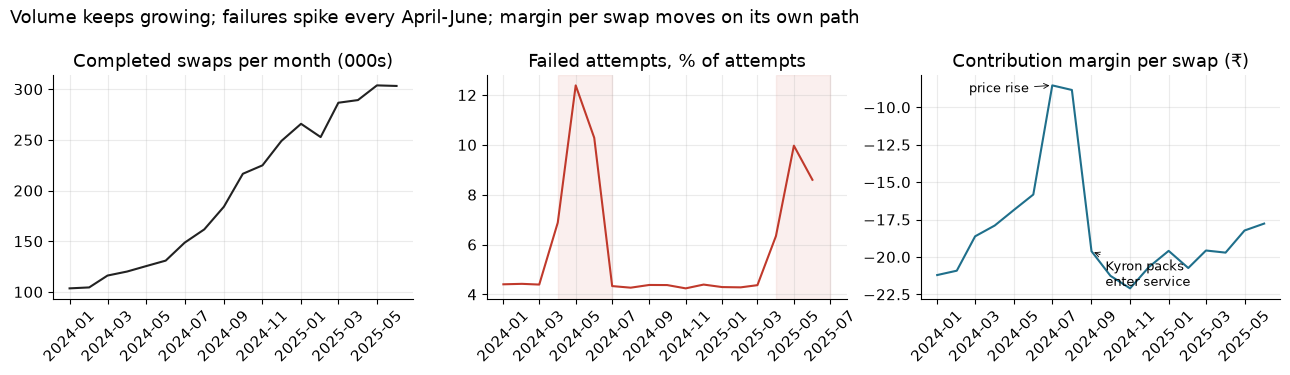

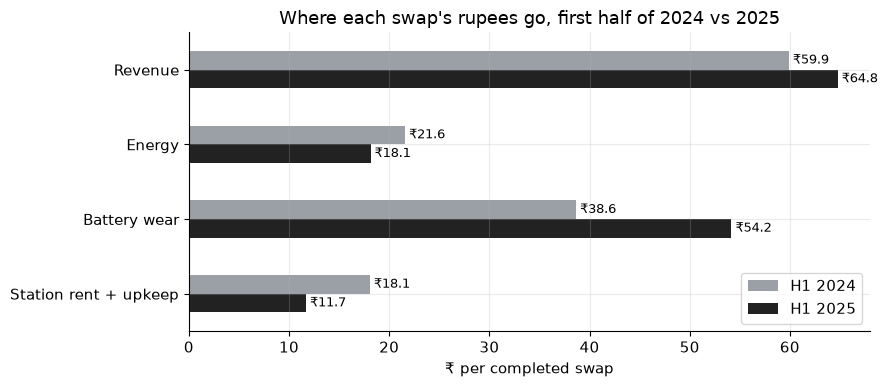

In [6]:
EOL_SOH = 70.0
for e_ in (60, 70, 80): fact(f"eol_option_{e_}", e_)
con.execute("""create or replace table batt as
with use as (select battery_out_id battery_id, count(*) swaps_served, min(ts) first_use from ev2 where ok group by 1)
select b.*, u.swaps_served, u.first_use,
  (b.initial_soh_pct - b.current_soh_pct) / nullif(u.swaps_served,0) soh_loss_per_swap
from raw_batteries b left join use u using(battery_id)""")

def wear_table(eol):
    return f"""select battery_id, purchase_cost_inr * soh_loss_per_swap / nullif(initial_soh_pct - {eol}, 0) wear_per_swap from batt"""

def monthly(eol=EOL_SOH, where="true"):
    return sql(f"""
with w as ({wear_table(eol)}),
sw as (select mon, count(*) attempts, sum(ok::int) done, sum(revenue) rev,
          sum(case when ok then kwh*grid_tariff_inr_kwh end) energy, sum(case when ok then w.wear_per_swap end) wear
       from ev2 left join w on w.battery_id = ev2.battery_out_id where {where} group by 1),
live as (select m.mon, sum(s.monthly_rent_inr + s.monthly_maintenance_inr) fixed, count(*) stations
         from (select distinct mon from ev2) m join st s
           on s.commissioned_date < m.mon + interval 1 month and (s.decommissioned_date is null or s.decommissioned_date >= m.mon)
         group by 1)
select sw.*, live.fixed, live.stations, 1 - done/attempts fail_rate,
  rev/done rev_per_swap, energy/done energy_per_swap, wear/done wear_per_swap, fixed/done fixed_per_swap,
  (rev - energy - wear - fixed)/done cm_per_swap
from sw join live using(mon) order by mon""")

M = monthly()
print(M[["mon","attempts","done","rev","stations","fail_rate","rev_per_swap","energy_per_swap","wear_per_swap","fixed_per_swap","cm_per_swap"]].round(3).to_string(index=False))
first, last = M.iloc[0], M.iloc[-1]
h1 = M[M.mon < "2024-07-01"]; h4 = M[M.mon >= "2025-01-01"]
fact("done_growth_x", last.done/first.done); fact("rev_growth_x", last.rev/first.rev)
fact("fail_jan24_pct", 100*first.fail_rate); fact("fail_may24_pct", 100*M[M.mon=="2024-05-01"].fail_rate.iloc[0])
fact("fail_may25_pct", 100*M[M.mon=="2025-05-01"].fail_rate.iloc[0]); fact("fail_jun25_pct", 100*last.fail_rate)
fails_first = first.attempts - first.done; fails_last = last.attempts - last.done
fact("fail_count_growth_x", fails_last/fails_first)
fact("cm_h1_2024", (h1.rev - h1.energy - h1.wear - h1.fixed).sum()/h1.done.sum())
fact("cm_h1_2025", (h4.rev - h4.energy - h4.wear - h4.fixed).sum()/h4.done.sum())
for k in ["rev","energy","wear","fixed"]:
    fact(f"{k}_per_swap_h1_2024", h1[k].sum()/h1.done.sum()); fact(f"{k}_per_swap_h1_2025", h4[k].sum()/h4.done.sum())
print(f"Completed swaps x{FACTS['done_growth_x']:.2f}, revenue x{FACTS['rev_growth_x']:.2f}, failed attempts x{FACTS['fail_count_growth_x']:.2f} (Jan 2024 -> Jun 2025)")
print(f"Margin per swap: H1 2024 ₹{FACTS['cm_h1_2024']:.2f} -> H1 2025 ₹{FACTS['cm_h1_2025']:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
x = pd.to_datetime(M.mon)
axes[0].plot(x, M.done/1e3, color=INK); axes[0].set_title("Completed swaps per month (000s)")
axes[1].plot(x, 100*M.fail_rate, color=ACCENT); axes[1].set_title("Failed attempts, % of attempts")
axes[1].axvspan(pd.Timestamp("2024-04-01"), pd.Timestamp("2024-07-01"), color=ACCENT, alpha=.08)
axes[1].axvspan(pd.Timestamp("2025-04-01"), pd.Timestamp("2025-07-01"), color=ACCENT, alpha=.08)
axes[2].plot(x, M.cm_per_swap, color=GOOD); axes[2].set_title("Contribution margin per swap (₹)")
axes[2].annotate("price rise", (pd.Timestamp("2024-07-01"), M.cm_per_swap[M.mon=="2024-07-01"].iloc[0]), xytext=(-60, -5), textcoords="offset points", fontsize=9, arrowprops=dict(arrowstyle="->", lw=.6))
axes[2].annotate("Kyron packs\nenter service", (pd.Timestamp("2024-09-01"), M.cm_per_swap[M.mon=="2024-09-01"].iloc[0]), xytext=(10, -25), textcoords="offset points", fontsize=9, arrowprops=dict(arrowstyle="->", lw=.6))
for a in axes: a.tick_params(axis="x", rotation=45)
fig.suptitle("Volume keeps growing; failures spike every April-June; margin per swap moves on its own path", x=0.01, ha="left")
savefig(fig, "q1_trends")

fig, ax = plt.subplots(figsize=(9, 4))
comp = pd.DataFrame({"H1 2024": [FACTS[f"{k}_per_swap_h1_2024"] for k in ["rev","energy","wear","fixed"]],
                     "H1 2025": [FACTS[f"{k}_per_swap_h1_2025"] for k in ["rev","energy","wear","fixed"]]},
                    index=["Revenue","Energy","Battery wear","Station rent + upkeep"])
comp.plot.barh(ax=ax, color=[MUTED, INK]); ax.invert_yaxis(); ax.set_xlabel("₹ per completed swap")
ax.set_title("Where each swap's rupees go, first half of 2024 vs 2025")
for c in ax.containers: ax.bar_label(c, fmt="₹%.1f", padding=3, fontsize=9)
savefig(fig, "q1_margin_parts")

## 4. Core question 2: where and when service fails
Hours use the corrected timestamps. Vehicle class comes from the rider.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

                           Jul-Mar  Apr-Jun
event_type                                 
abandoned_queue               1.26     2.66
cancelled_by_rider            0.43     0.44
failed_no_charged_battery     2.35     5.45
failed_system_error           0.30     0.30
swap_completed               95.66    91.16
vehicle_class  summer      f
           2W   False 0.0377
           2W    True 0.0836
           3W   False 0.0905
           3W    True 0.1267
The worst 15 of 150 stations hold 24.1% of failed attempts and 17.2% of attempts


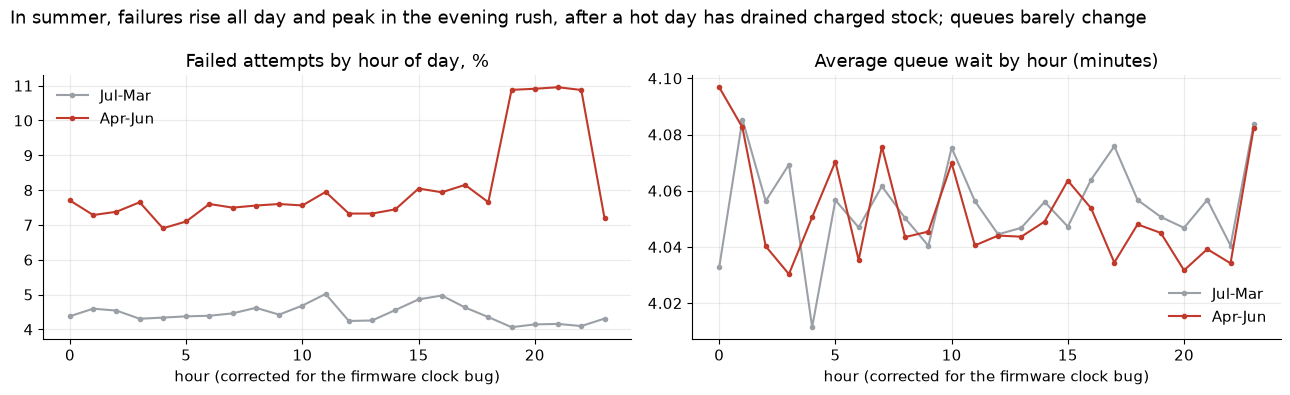

10.95412747305714

In [7]:
con.execute("""create or replace table evr as select ev2.*, r.vehicle_class, r.partner_id, r.plan_type from ev2 join raw_riders r using(rider_id)""")
by_season = sql("""select summer, event_type, count(*) n from evr group by all""").pivot(index="event_type", columns="summer", values="n")
by_season = (100*by_season/by_season.sum()).round(2); by_season.columns = ["Jul-Mar", "Apr-Jun"]
print(by_season.to_string())
fact("nobatt_share_of_fail_summer_pct", 100*sql("select avg((event_type='failed_no_charged_battery')::int) v from evr where summer and not ok").v[0])
hr = sql("select h, summer, 1-avg(ok::int) f, avg(queue_wait_sec)/60 q from evr group by all order by h")
vc = sql("select vehicle_class, summer, 1-avg(ok::int) f from evr group by all order by all")
print(vc.round(4).to_string(index=False))
for _, r in vc.iterrows(): fact(f"fail_{r.vehicle_class}_{'summer' if r.summer else 'other'}_pct", 100*r.f)

stf = sql("select station_id, count(*) n, sum((not ok)::int) f from evr group by 1 order by f desc")
stf["cum"] = stf.f.cumsum()/stf.f.sum()
top10 = int(round(0.1*len(stf)))
fact("stations_n", len(stf)); fact("top10pct_stations_fail_share_pct", 100*stf.f.iloc[:top10].sum()/stf.f.sum())
fact("top10pct_stations_attempt_share_pct", 100*stf.n.iloc[:top10].sum()/stf.n.sum())
print(f"The worst {top10} of {len(stf)} stations hold {FACTS['top10pct_stations_fail_share_pct']:.1f}% of failed attempts and {FACTS['top10pct_stations_attempt_share_pct']:.1f}% of attempts")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for s, c, lab in [(False, MUTED, "Jul-Mar"), (True, ACCENT, "Apr-Jun")]:
    d = hr[hr.summer == s]
    axes[0].plot(d.h, 100*d.f, color=c, label=lab, marker="o", ms=3)
    axes[1].plot(d.h, d.q, color=c, label=lab, marker="o", ms=3)
axes[0].set_title("Failed attempts by hour of day, %"); axes[1].set_title("Average queue wait by hour (minutes)")
for a in axes: a.set_xlabel("hour (corrected for the firmware clock bug)"); a.legend(frameon=False)
fig.suptitle("In summer, failures rise all day and peak in the evening rush, after a hot day has drained charged stock; queues barely change", x=0.01, ha="left")
savefig(fig, "q2_hours")
pk = hr[hr.summer].sort_values("f", ascending=False).iloc[0]
ev_s = hr[hr.summer & hr.h.between(19, 22)]; day_s = hr[hr.summer & ~hr.h.between(19, 22)]
fact("summer_fail_evening_pct", 100*ev_s.f.mean()); fact("summer_fail_rest_of_day_pct", 100*day_s.f.mean())
fact("summer_peak_fail_hour", pk.h); fact("summer_peak_fail_hour_pct", 100*pk.f)

## 5. Core question 3: stations, equipment and the heat mechanism
Charger generation, city and season together explain where failures happen. Hourly cabinet telemetry shows why. We also test whether the empty shelf itself is the cause, comparing hours at the same station and cabinet temperature: if it were, extra packs would be the cheap fix.

Apr-Jun failure %, charger generation x city
 city  Bengaluru  Delhi NCR  Hyderabad  Jaipur  Mumbai  Pune
gen                                                        
Gen1        5.3       17.0       13.5    17.2     4.5   7.8
Gen2        4.7        8.8        7.8     9.1     4.5   5.6
Gen3        4.5        5.7        5.1     5.7     4.4   4.8


 band  gen      n    chg  zero  quar
35-40 Gen1  35200  88.01  0.01  0.00
35-40 Gen2  46611  63.99  0.00  0.00
35-40 Gen3  13420  42.02  0.00  0.00
40-45 Gen1  35152 101.10  0.02  0.01
40-45 Gen2  27101  65.97  0.01  0.01
40-45 Gen3  11566  42.34  0.00  0.01
  45+ Gen1  29638 155.63  0.37  0.01
  45+ Gen2  11995  72.11  0.01  0.01
  45+ Gen3   7996  43.47  0.00  0.01
  <35 Gen1 549452  87.99  0.01  0.00
  <35 Gen2 558938  64.00  0.00  0.00
  <35 Gen3  88256  42.01  0.00  0.00
 gen  hot_share
Gen1      0.137
Gen2      0.057
Gen3      0.106


 is_empty     fail
    False 0.058910
     True 0.116077


Gen1, 2W riders: 'no charged pack' failures by cabinet temperature and whether the cabinet showed zero charged 2W packs
                       n       nb    pct
band  is_empty                         
35-45 False      256673  19343.0   7.54
      True         3519    236.0   6.71
45+   False       64364   6986.0  10.85
      True        30077   2787.0   9.27
<35   False     1215097  33413.0   2.75
      True         8256    183.0   2.22


Same station, same temperature band (145 strata): odds of a 'no charged pack' failure when the cabinet shows zero packs, vs packs in stock: 0.82 [0.79, 0.86]


Same station, same month: odds of a failed attempt in hotter hours vs the station's own hours below 35C
  gen cabinet temp vs <35  odds ratio  lo95  hi95
Gen1               35-40        1.19  1.10  1.29
Gen1               40-45        1.55  1.43  1.68
Gen1                 45+        1.45  1.30  1.60
Gen2               35-40        0.69  0.63  0.76
Gen2               40-45        0.79  0.71  0.88
Gen2                 45+        0.88  0.79  0.99
Gen3               35-40        0.79  0.73  0.86
Gen3               40-45        0.80  0.73  0.88
Gen3                 45+        0.71  0.64  0.78


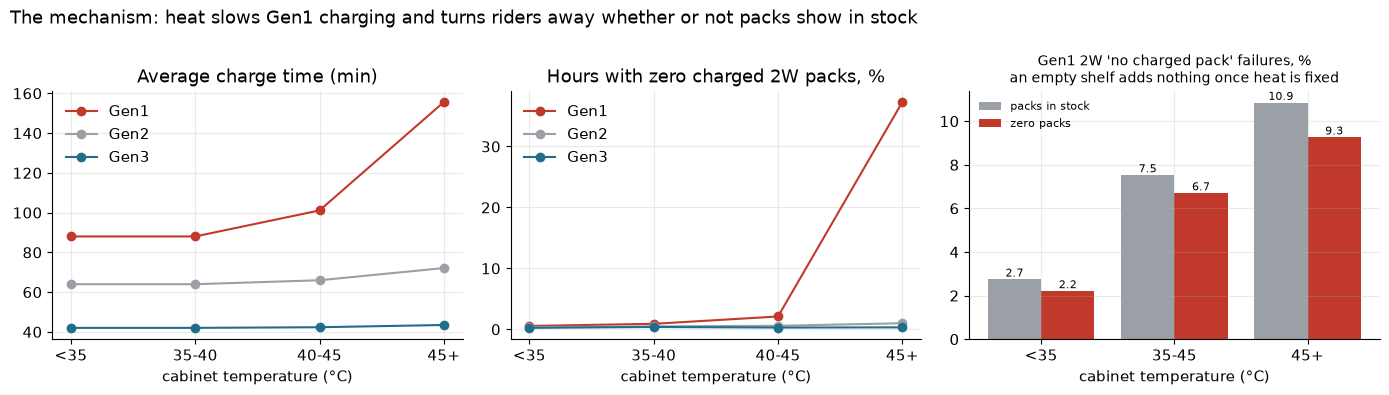

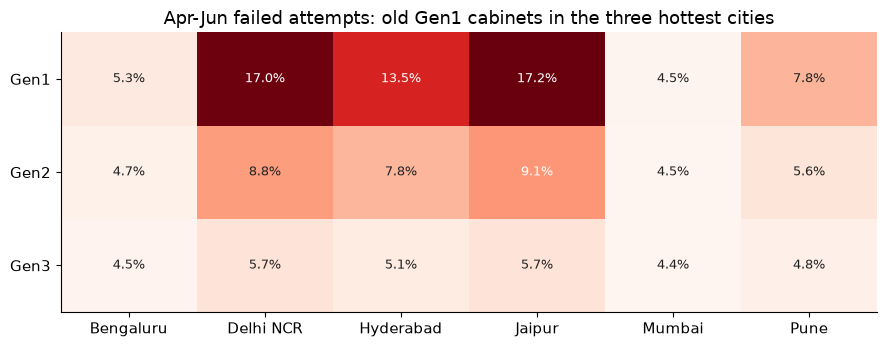

In [8]:
gc = sql("""select gen, city, summer, count(*) n, 1-avg(ok::int) f from evr group by all""")
piv = gc[gc.summer].pivot(index="gen", columns="city", values="f")*100
print("Apr-Jun failure %, charger generation x city\n", piv.round(1).to_string())
g = sql("select gen, summer, 1-avg(ok::int) f from evr group by all order by all")
for _, r in g.iterrows(): fact(f"fail_{r.gen}_{'summer' if r.summer else 'other'}_pct", 100*r.f)
nbm = sql("select gen, avg((event_type='failed_no_charged_battery')::int) filter (where not ok) nb from evr where summer group by 1")
for _, r in nbm.iterrows(): fact(f"nobatt_share_of_fails_summer_{r.gen}_pct", 100*r.nb)
c = sql("select city, 1-avg(ok::int) f from evr where summer group by 1 order by 2 desc")
for _, r in c.iterrows(): fact(f"fail_summer_{r.city.replace(' ','_')}_pct", 100*r.f)
gen1_hot = sql("select count(*) n from st where charger_generation='Gen1' and city in ('Jaipur','Delhi NCR','Hyderabad')").n[0]
fact("gen1_stations", sql("select count(*) n from st where charger_generation='Gen1'").n[0]); fact("gen1_hot_city_stations", gen1_hot)

tele = sql("""select case when cabinet_temp_c<35 then '<35' when cabinet_temp_c<40 then '35-40' when cabinet_temp_c<45 then '40-45' else '45+' end band,
   s.charger_generation gen, count(*) n, avg(avg_charge_minutes) chg, avg((charged_2w_min=0)::int) zero, avg(packs_quarantined) quar
   from raw_station_hourly_status h join st s using(station_id) where telemetry_status='ok' group by all order by all""")
tb = sql("""select case when cabinet_temp_c<35 then '<35' when cabinet_temp_c<40 then '35-40' when cabinet_temp_c<45 then '40-45' else '45+' end band,
   count(*) n, avg(avg_charge_minutes) chg, avg((charged_2w_min=0)::int) zero from raw_station_hourly_status h join st using(station_id)
   where telemetry_status='ok' group by 1 order by 1""")
print(tele.round(2).to_string(index=False))
lo, hi = tb[tb.band=="<35"].iloc[0], tb[tb.band=="45+"].iloc[0]
fact("chg_min_cool", lo.chg); fact("chg_min_hot", hi.chg); fact("zero_stock_cool_pct", 100*lo.zero); fact("zero_stock_hot_pct", 100*hi.zero)
hot_by_gen = sql("""select s.charger_generation gen, avg((cabinet_temp_c>=45)::int) hot_share
   from raw_station_hourly_status h join st s using(station_id) where telemetry_status='ok' and month(hour_start) in (4,5,6) group by 1 order by 1""")
for _, r in hot_by_gen.iterrows(): fact(f"hot_hours_summer_{r.gen}_pct", 100*r.hot_share)
print(hot_by_gen.round(3).to_string(index=False))

# Link telemetry to swaps: failure rate in station-hours with zero charged 2W packs vs with stock
link = sql("""with e as (select station_id, date_trunc('hour', ts) hr, count(*) n, sum((not ok)::int) f from evr group by all)
 select (h.charged_2w_min=0) is_empty, sum(e.f)/sum(e.n) fail from e join raw_station_hourly_status h on h.station_id=e.station_id and h.hour_start=e.hr
 where h.telemetry_status='ok' group by 1""")
print(link.to_string(index=False))
fact("fail_in_empty_hours_pct", 100*link[link.is_empty].fail.iloc[0]); fact("fail_in_stocked_hours_pct", 100*link[~link.is_empty].fail.iloc[0])
# Is the empty shelf the cause, or a symptom of the heat? Compare hours at the SAME station and cabinet-temperature band.
# For each attempt, use the charged stock for the rider's own vehicle class (2W or 3W) in that station-hour.
from statsmodels.stats.contingency_tables import StratifiedTable
sk = sql("""with e as (select e.station_id, e.vehicle_class vc, date_trunc('hour', e.ts) hr, count(*) n,
   sum((e.event_type='failed_no_charged_battery')::int) nb from evr e where e.gen='Gen1' group by all)
 select e.*, case when vc='3W' then h.charged_3w_min else h.charged_2w_min end stock,
   case when cabinet_temp_c<35 then '<35' when cabinet_temp_c<45 then '35-45' else '45+' end band
 from e join raw_station_hourly_status h on h.station_id=e.station_id and h.hour_start=e.hr where h.telemetry_status='ok'""")
sk = sk[sk.stock.notna() & (sk.vc == "2W")]
sk["is_empty"] = sk.stock == 0
byb = sk.groupby(["band", "is_empty"])[["n", "nb"]].sum(); byb["pct"] = 100*byb.nb/byb.n
print("Gen1, 2W riders: 'no charged pack' failures by cabinet temperature and whether the cabinet showed zero charged 2W packs\n", byb.round(2).to_string())
for b, key in [("<35", "cool"), ("45+", "hot")]:
    fact(f"nb_g1_{key}_empty_pct", byb.loc[(b, True), "pct"]); fact(f"nb_g1_{key}_stocked_pct", byb.loc[(b, False), "pct"])
fact("nb_g1_2w_with_stock_pct", 100*sk[~sk.is_empty].nb.sum()/sk.nb.sum())
tabs = []
for _, d in sk.groupby(["station_id", "band"]):
    a = d.groupby("is_empty")[["n", "nb"]].sum()
    if len(a) == 2: tabs.append(np.array([[a.nb[True], a.n[True]-a.nb[True]], [a.nb[False], a.n[False]-a.nb[False]]]))
mh = StratifiedTable(tabs)
fact("stock_mh_or", mh.oddsratio_pooled); lo_, hi_ = mh.oddsratio_pooled_confint(); fact("stock_mh_or_lo", lo_); fact("stock_mh_or_hi", hi_)
fact("stock_mh_strata", len(tabs))
print(f"Same station, same temperature band ({len(tabs)} strata): odds of a 'no charged pack' failure when the cabinet shows zero packs, "
      f"vs packs in stock: {mh.oddsratio_pooled:.2f} [{lo_:.2f}, {hi_:.2f}]")
# Within-station test of the heat effect: does the same cabinet fail more in its own hot hours, holding the month and the evening rush fixed?
# Binomial model on station x month x temperature band x evening cells, one dummy per station, errors clustered by station.
import statsmodels.api as sm, statsmodels.formula.api as smf
fe = sql("""with e as (select station_id, date_trunc('hour', ts) hr, count(*) n, sum((not ok)::int) f from evr group by all)
 select e.station_id, s.charger_generation gen, strftime(e.hr, '%Y-%m') mon, hour(e.hr) between 19 and 21 eve,
   case when cabinet_temp_c<35 then 'a<35' when cabinet_temp_c<40 then 'b35-40' when cabinet_temp_c<45 then 'c40-45' else 'd45+' end band,
   sum(n) n, sum(f) f
 from e join raw_station_hourly_status h on h.station_id=e.station_id and h.hour_start=e.hr join st s on s.station_id=e.station_id
 where h.telemetry_status='ok' group by all""")
fe["ok_n"] = fe.n - fe.f
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # station dummies absorb generation; the band-by-generation terms are still identified against each generation's <35 band
    fem = smf.glm("f + ok_n ~ C(station_id) + C(mon) + eve + C(band):C(gen)", data=fe, family=sm.families.Binomial()).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(fe.station_id)[0]})
fe_rows = []
for gname in ["Gen1", "Gen2", "Gen3"]:
    for b in ["b35-40", "c40-45", "d45+"]:
        k = f"C(band)[T.{b}]:C(gen)[{gname}]"; lo_, hi_ = np.exp(fem.conf_int().loc[k])
        fe_rows.append((gname, b[1:], np.exp(fem.params[k]), lo_, hi_))
fe_tab = pd.DataFrame(fe_rows, columns=["gen", "cabinet temp vs <35", "odds ratio", "lo95", "hi95"])
print("Same station, same month: odds of a failed attempt in hotter hours vs the station's own hours below 35C\n", fe_tab.round(2).to_string(index=False))
for _, r in fe_tab[fe_tab["cabinet temp vs <35"] == "45+"].iterrows():
    fact(f"fe_or_hot_{r.gen}", r["odds ratio"]); fact(f"fe_or_hot_{r.gen}_lo", r.lo95); fact(f"fe_or_hot_{r.gen}_hi", r.hi95)
fact("fe_stations", fe.station_id.nunique())
for _, r in tele[tele.band.isin(["<35","45+"])].iterrows():
    fact(f"chg_min_{r.gen}_{'hot' if r.band=='45+' else 'cool'}", r.chg); fact(f"zero_stock_{r.gen}_{'hot' if r.band=='45+' else 'cool'}_pct", 100*r.zero)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
order = ["<35","35-40","40-45","45+"]
for gname, col in [("Gen1", ACCENT), ("Gen2", MUTED), ("Gen3", GOOD)]:
    d = tele[tele.gen == gname].set_index("band").loc[order]
    axes[0].plot(order, d.chg, marker="o", color=col, label=gname)
    axes[1].plot(order, 100*d.zero, marker="o", color=col, label=gname)
axes[0].set_title("Average charge time (min)"); axes[1].set_title("Hours with zero charged 2W packs, %")
for a in axes[:2]: a.set_xlabel("cabinet temperature (°C)"); a.legend(frameon=False)
bands3 = ["<35", "35-45", "45+"]; xx = np.arange(3)
for off, emp, col, lab in [(-0.2, False, MUTED, "packs in stock"), (0.2, True, ACCENT, "zero packs")]:
    vals = [byb.loc[(b, emp), "pct"] for b in bands3]
    axes[2].bar(xx+off, vals, width=0.4, color=col, label=lab)
    for x_, v in zip(xx+off, vals): axes[2].annotate(f"{v:.1f}", (x_, v), ha="center", va="bottom", fontsize=8)
axes[2].set_xticks(xx, bands3); axes[2].set_xlabel("cabinet temperature (°C)"); axes[2].legend(frameon=False, fontsize=8)
axes[2].set_title("Gen1 2W 'no charged pack' failures, %\nan empty shelf adds nothing once heat is fixed", fontsize=10)
fig.suptitle("The mechanism: heat slows Gen1 charging and turns riders away whether or not packs show in stock", x=0.01, ha="left")
savefig(fig, "q3_mechanism")

fig, ax = plt.subplots(figsize=(9, 3.6))
im = ax.imshow(piv.values, cmap="Reds", aspect="auto")
ax.set_xticks(range(len(piv.columns)), piv.columns); ax.set_yticks(range(len(piv.index)), piv.index)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j]
        if not np.isnan(v): ax.text(j, i, f"{v:.1f}%", ha="center", va="center", fontsize=9, color="white" if v > 9 else INK)
ax.set_title("Apr-Jun failed attempts: old Gen1 cabinets in the three hottest cities"); ax.grid(False)
savefig(fig, "q3_gen_city")

### The weather link: a forecast trigger for operations
Daily city weather (city_daily_context) joined to each day's attempts. Context: lithium-ion cells are commonly charged only between 0°C and 45°C (Battery University, a secondary source), which matches where Gen1 cabinets break down.

Failed attempts % by the day's maximum temperature
 gen    Gen1  Gen2  Gen3
band                   
<=30    4.3   4.4   4.3
30-34   4.4   4.4   4.4
34-36   6.0   5.0   4.6
36-38  14.9   7.8   5.4
38-40  19.2   9.5   5.8
40-44  19.3  10.0   5.8
44+    19.6   9.8   6.0
     city  d36
Delhi NCR   81
Bengaluru    6
   Jaipur   80
   Mumbai    0
     Pune   28
Hyderabad   60
Each hour of city-wide grid outage adds 2.1 points to that day's failure rate (p=0.000)


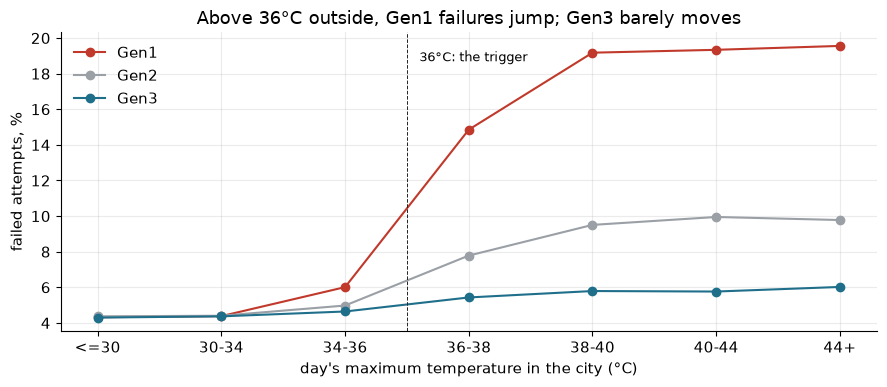

 gen  tickets       n  per_10k
Gen3     4490  372241   120.62
Gen2    15313 1620707    94.48
Gen1    21435 1822034   117.64
    location_type      f      n
   commercial_hub 0.0958 543925
           market 0.0923 479523
      transit_hub 0.0864  64296
      residential 0.0770 125687
        tech_park 0.0664  51491
highway_fuel_pump 0.0636 131077


In [9]:
wd = sql("""select e.city, e.gen, e.ts::date d, count(*) n, avg((not e.ok)::int) f, c.max_temp_c, c.grid_outage_hours, c.rainfall_mm
   from evr e join raw_city_daily_context c on c.city = e.city and c.date = e.ts::date group by all""")
wd["band"] = pd.cut(wd.max_temp_c, [0, 30, 34, 36, 38, 40, 44, 50], labels=["<=30", "30-34", "34-36", "36-38", "38-40", "40-44", "44+"])
wb = wd.groupby(["band", "gen"]).apply(lambda g: 100*np.average(g.f, weights=g.n)).unstack()
print("Failed attempts % by the day's maximum temperature\n", wb.round(1).to_string())
for gname in ["Gen1", "Gen3"]:
    fact(f"wx_fail_{gname}_le34_pct", 100*np.average(wd[(wd.gen == gname) & (wd.max_temp_c <= 34)].f, weights=wd[(wd.gen == gname) & (wd.max_temp_c <= 34)].n))
    fact(f"wx_fail_{gname}_ge38_pct", 100*np.average(wd[(wd.gen == gname) & (wd.max_temp_c > 38)].f, weights=wd[(wd.gen == gname) & (wd.max_temp_c > 38)].n))
wm = smf.wls("f ~ C(gen)*max_temp_c + grid_outage_hours + rainfall_mm + C(city)", wd, weights=wd.n).fit(cov_type="cluster", cov_kwds={"groups": wd.city})
fact("wx_outage_pts_per_hour", 100*wm.params["grid_outage_hours"]); fact("wx_outage_p", wm.pvalues["grid_outage_hours"])
hotdays = sql("""select city, count(*) filter (where max_temp_c >= 36) d36 from raw_city_daily_context where year(date)=2025 and month(date) in (4,5,6) group by 1""")
for _, r in hotdays.iterrows(): fact(f"hot_days_2025_{r.city.replace(' ','_')}", r.d36)
print(hotdays.to_string(index=False))
print(f"Each hour of city-wide grid outage adds {FACTS['wx_outage_pts_per_hour']:.1f} points to that day's failure rate (p={FACTS['wx_outage_p']:.3f})")
fig, ax = plt.subplots(figsize=(9, 4))
for gname, col in [("Gen1", ACCENT), ("Gen2", MUTED), ("Gen3", GOOD)]:
    ax.plot(wb.index.astype(str), wb[gname], marker="o", color=col, label=gname)
ax.axvline(2.5, color=INK, lw=.7, ls="--"); ax.text(2.6, ax.get_ylim()[1]*0.92, "36°C: the trigger", fontsize=9)
ax.set_xlabel("day's maximum temperature in the city (°C)"); ax.set_ylabel("failed attempts, %"); ax.legend(frameon=False)
ax.set_title("Above 36°C outside, Gen1 failures jump; Gen3 barely moves")
savefig(fig, "q3_weather")

tk = sql("""select s.charger_generation gen, count(t.ticket_id) tickets from raw_support_tickets t join st s using(station_id) group by 1""")
sw_by_gen = sql("select gen, count(*) n from evr group by 1")
tk = tk.merge(sw_by_gen, on="gen"); tk["per_10k"] = 1e4*tk.tickets/tk.n
print(tk.round(2).to_string(index=False))
for _, r in tk.iterrows(): fact(f"tickets_per10k_{r.gen}", r.per_10k)
loc = sql("select location_type, 1-avg(ok::int) f, count(*) n from evr where summer group by 1 order by 2 desc")
print(loc.round(4).to_string(index=False))

## 6. Core question 4: batteries and the new supplier
Pack health is measured from each pack's own swaps (ledger commission dates are unreliable, see section 2).

supplier pack_type  packs  soh_lost  swaps  soh_loss_per_100  retired  soh_now
  Amptek 2W_2.1kWh   1098     19.24 643.06              3.00      0.0    79.96
 Cellora 2W_2.1kWh   3035     19.21 643.15              2.99      0.0    79.97
   Kyron 2W_2.1kWh   1385     38.67 401.71              9.65   1385.0    60.53
  Amptek 3W_4.8kWh    209     12.69 377.38              3.37      0.0    86.51
 Cellora 3W_4.8kWh    520     12.67 378.66              3.36      0.0    86.52
   Kyron 3W_4.8kWh    253     17.90 381.38              4.70     53.0    81.35
supplier manufacturing_lot pack_type  packs  soh_loss_per_100
   Kyron           KY-2408 2W_2.1kWh    471              9.66
   Kyron           KY-2409 2W_2.1kWh    462              9.65
   Kyron           KY-2407 2W_2.1kWh    452              9.64
  Amptek           AM-2506 2W_2.1kWh     38              3.05
  Amptek           AM-2405 2W_2.1kWh     76              3.03
 Cellora           CE-2303 2W_2.1kWh    109              3.03
  Amptek     

supplier pack_type   wear
  Amptek 2W_2.1kWh  32.79
 Cellora 2W_2.1kWh  32.74
   Kyron 2W_2.1kWh 105.46
  Amptek 3W_4.8kWh  78.09
 Cellora 3W_4.8kWh  77.92
   Kyron 3W_4.8kWh 109.20
Kyron packs served 652,854 swaps; their extra wear over other suppliers' packs: ₹4.35 crore
Supplier of the battery named on each ticket, % of tickets by category
 supplier              Amptek  Cellora  Kyron
category                                    
app_issue               17.8     49.1   33.1
billing_dispute         22.1     63.7   14.1
long_queue              20.2     54.4   25.4
low_range               17.6     48.2   34.2
no_battery_available    20.2     55.1   24.6
other                   18.6     47.8   33.5


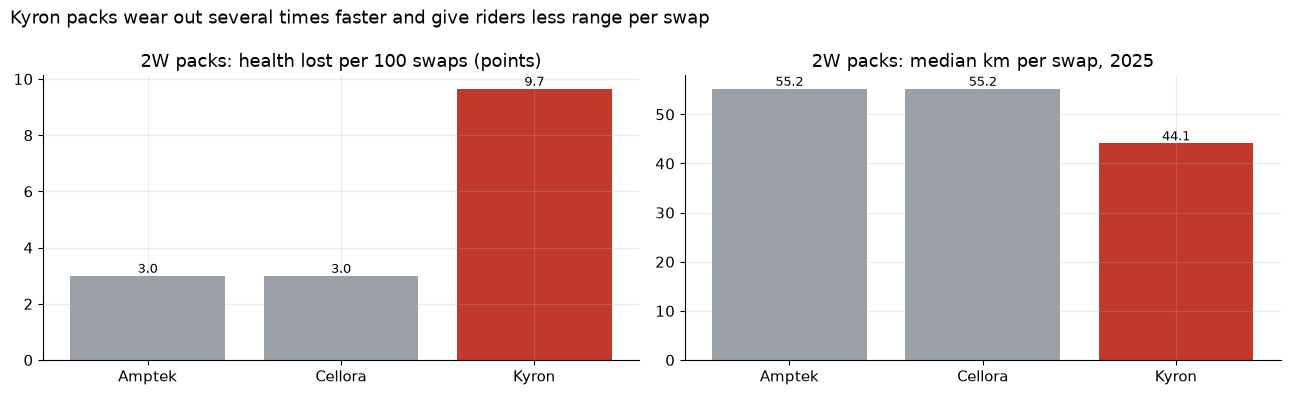

In [10]:
sup = sql("""select supplier, pack_type, count(*) packs, avg(initial_soh_pct-current_soh_pct) soh_lost, avg(swaps_served) swaps,
   100*avg(soh_loss_per_swap) soh_loss_per_100, sum((retired_date is not null)::int) retired, avg(current_soh_pct) soh_now
   from batt group by all order by pack_type, supplier""")
print(sup.round(2).to_string(index=False))
lots = sql("""select supplier, manufacturing_lot, pack_type, count(*) packs, 100*avg(soh_loss_per_swap) soh_loss_per_100
   from batt where pack_type like '2W%' group by all order by soh_loss_per_100 desc limit 8""")
print(lots.round(2).to_string(index=False))
for _, r in sup.iterrows():
    k = f"{r.supplier}_{r.pack_type[:2]}"
    fact(f"soh_loss_per100_{k}", r.soh_loss_per_100); fact(f"soh_now_{k}", r.soh_now); fact(f"packs_{k}", r.packs); fact(f"retired_{k}", r.retired)
rng = sql("""select b.supplier, b.pack_type, median(e.km) km, count(*) n from evr e join batt b on b.battery_id=e.battery_in_id
   where e.ok and e.km is not null and e.y=2025 group by all order by 2,1""")
print(rng.to_string(index=False))
for _, r in rng.iterrows(): fact(f"km_median_2025_{r.supplier}_{r.pack_type[:2]}", r.km)

wear = sql(f"""with w as ({wear_table(EOL_SOH)})
   select b.supplier, b.pack_type, avg(w.wear_per_swap) wear from evr e join batt b on b.battery_id=e.battery_out_id join w using(battery_id)
   where e.ok group by all""")
print(wear.round(2).to_string(index=False))
k2 = sql(f"""with w as ({wear_table(EOL_SOH)}), x as (select b.supplier='Kyron' kyron, b.pack_type, w.wear_per_swap from evr e
   join batt b on b.battery_id=e.battery_out_id join w using(battery_id) where e.ok)
   select pack_type, avg(wear_per_swap) filter (where kyron) ky, avg(wear_per_swap) filter (where not kyron) oth,
          count(*) filter (where kyron) n_ky from x group by 1""")
excess = float(((k2.ky - k2.oth)*k2.n_ky).sum())
fact("kyron_excess_wear_inr", excess); fact("kyron_excess_wear_cr", excess/1e7)
fact("kyron_swaps_served", k2.n_ky.sum())
fact("kyron_wear_2w", k2[k2.pack_type.str.startswith("2W")].ky.iloc[0]); fact("other_wear_2w", k2[k2.pack_type.str.startswith("2W")].oth.iloc[0])
print(f"Kyron packs served {int(k2.n_ky.sum()):,} swaps; their extra wear over other suppliers' packs: ₹{excess/1e7:.2f} crore")

# Ticket text: the 'other' bucket is battery complaints blamed on the vehicle
tix = sql("""select t.category, b.supplier, count(*) n from raw_support_tickets t left join raw_batteries b using(battery_id)
   where t.battery_id is not null group by all""").pivot(index="category", columns="supplier", values="n").fillna(0)
tix_share = (100*tix.div(tix.sum(1), axis=0)).round(1)
print("Supplier of the battery named on each ticket, % of tickets by category\n", tix_share.to_string())
fact("kyron_share_lowrange_tickets_pct", tix_share.loc["low_range", "Kyron"]); fact("kyron_share_other_tickets_pct", tix_share.loc["other", "Kyron"])
fact("kyron_share_billing_tickets_pct", tix_share.loc["billing_dispute", "Kyron"])
fact("kyron_share_of_packs_pct", 100*sql("select avg((supplier='Kyron')::int) v from raw_batteries").v[0])
fact("other_tickets", sql("select count(*) n from raw_support_tickets where category='other'").n[0])
fact("lowrange_tickets", sql("select count(*) n from raw_support_tickets where category='low_range'").n[0])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
s2 = sup[sup.pack_type.str.startswith("2W")]
axes[0].bar(s2.supplier, s2.soh_loss_per_100, color=[ACCENT if s == "Kyron" else MUTED for s in s2.supplier])
axes[0].set_title("2W packs: health lost per 100 swaps (points)")
r2 = rng[rng.pack_type.str.startswith("2W")]
axes[1].bar(r2.supplier, r2.km, color=[ACCENT if s == "Kyron" else MUTED for s in r2.supplier]); axes[1].set_title("2W packs: median km per swap, 2025")
for a in axes:
    for p in a.patches: a.annotate(f"{p.get_height():.1f}", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom", fontsize=9)
fig.suptitle("Kyron packs wear out several times faster and give riders less range per swap", x=0.01, ha="left")
savefig(fig, "q4_kyron")

## 7. Core question 5: pricing and partner economics
**Base price change (July 2024).** **Peak/off-peak pilot (Bengaluru and Pune from October 2024)**, measured as a difference-in-differences against the four other cities, with a pre-period check. **Partner contracts**, compared on contribution margin, not revenue.

 indep  post  per_rider_week
 False False           6.148
 False  True           6.306
  True False           4.972
  True  True           5.153
PEAK hours: [12, 13, 19, 20, 21, 22]  OFFPEAK hours: [0, 1, 2, 3, 4, 5, 14, 15, 16, 23]
DiD peak_share: -0.0313  95% CI [-0.0361, -0.0264]  p=0.000
DiD rev: 5.4076  95% CI [4.946, 5.8693]  p=0.000
DiD peak_fail: 0.0057  95% CI [-0.0008, 0.0121]  p=0.085


Permutation: real pilot effect ranks 1 of 15 possible city pairs by size


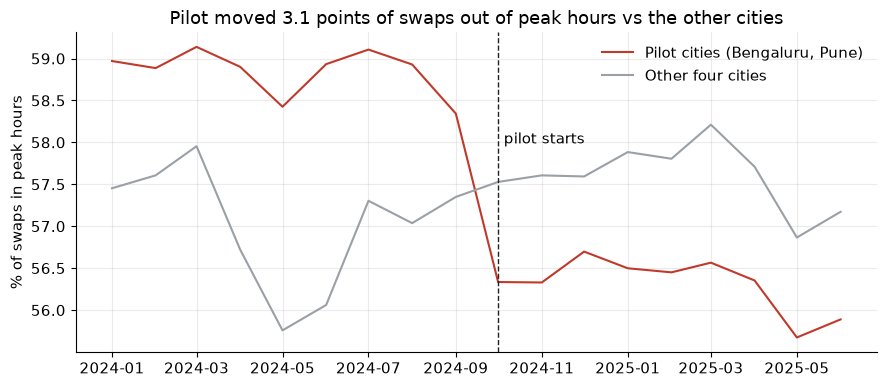

Placebo (fake start April 2024, pre-period only): +0.67 points, p=0.01; real effect -3.13 points
           partner  swaps    rev     cm    cm_total
Independent riders 581013  70.10 -11.89 -6910192.34
           ZipDrop 262396  48.64 -33.85 -8881548.79
          FeastFly 245889  63.98 -17.74 -4361296.43
        ParcelNest 137592  57.53 -24.71 -3399908.85
        Swiggle Go 111004  60.31 -21.65 -2403159.63
          CargoTuk  62042 101.38 -36.12 -2240972.10
         QuickCart  58755  64.26 -17.04 -1001245.35
         RideMitra  58741  64.09 -17.52 -1029015.95
       DabbaXpress  44433  65.46 -16.21  -720085.68
         MetroMove  40313  59.59 -23.08  -930571.62
       LastMileHub  38493  61.42 -21.45  -825840.34
       UrbanErrand  36557  65.08 -16.83  -615391.12
          HaulKing  24191 102.44 -35.27  -853187.86
ZipDrop revenue per swap 59.60 -> 48.65; the amendment gave away ₹36.9 lakh to Jun 2025


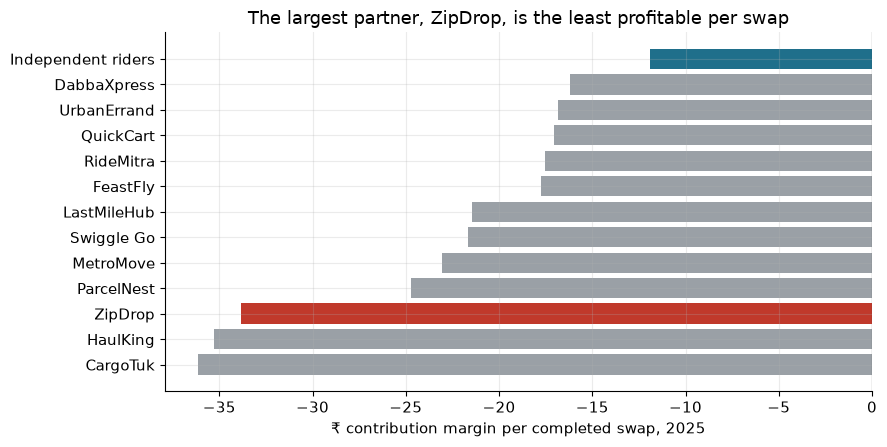

In [11]:
price = sql("""select date_trunc('month', ts) mon, avg(list_price_inr) filter (where tariff_code='STD') std_list, avg(revenue) filter (where ok) rev from evr group by 1 order by 1""")
pre_p, post_p = price[price.mon < "2024-07-01"].std_list.mean(), price[(price.mon >= "2024-07-01")].std_list.mean()
fact("std_list_before", pre_p); fact("std_list_after", post_p)
# swaps per active rider per week around the change, independents (pay their own price) vs partner riders
spr = sql("""select r.partner_id is null indep, ts >= '2024-07-01' post, count(*) filter (where ok) / count(distinct rider_id || '-' || week(ts) || '-' || year(ts)) per_rider_week
   from evr r where ts between '2024-05-01' and '2024-08-31' group by all order by all""")
print(spr.round(3).to_string(index=False))

# Pilot windows from the data: hours where a tariff covers at least 10% of pilot-city swaps after launch
tw = sql("""select h, avg((tariff_code='PEAK')::int) peak, avg((tariff_code='OFFPEAK')::int) off from evr
   where city in ('Bengaluru','Pune') and ts >= '2024-10-01' and ok group by 1 order by 1""")
peak_hours = tw[tw.peak >= 0.10].h.tolist(); off_hours = tw[tw.off >= 0.10].h.tolist()
print("PEAK hours:", peak_hours, " OFFPEAK hours:", off_hours)
ph = ",".join(map(str, peak_hours))
cm_city = sql(f"""select city, mon, avg((h in ({ph}))::int) filter (where ok) peak_share, count(*) n,
   avg(revenue) filter (where ok) rev, 1-avg(ok::int) filter (where h in ({ph})) peak_fail
   from evr group by all""")
cm_city["treated"] = cm_city.city.isin(["Bengaluru", "Pune"]).astype(int)
cm_city["post"] = (pd.to_datetime(cm_city.mon) >= "2024-10-01").astype(int)
did = {}
for y in ["peak_share", "rev", "peak_fail"]:
    m = smf.wls(f"{y} ~ treated:post + C(city) + C(mon)", data=cm_city, weights=cm_city.n).fit(cov_type="cluster", cov_kwds={"groups": cm_city.city})
    did[y] = (m.params["treated:post"], m.conf_int().loc["treated:post"].tolist(), m.pvalues["treated:post"])
    print(f"DiD {y}: {m.params['treated:post']:.4f}  95% CI {m.conf_int().loc['treated:post'].round(4).tolist()}  p={m.pvalues['treated:post']:.3f}")
# Exact permutation test: the pilot effect if any 2 of the 6 cities had been the pilot
from itertools import combinations
cities6 = sorted(cm_city.city.unique()); perm = []
for pair in combinations(cities6, 2):
    d_ = cm_city.assign(treated=cm_city.city.isin(pair).astype(int))
    fit_ = smf.wls("peak_share ~ treated:post + C(city) + C(mon)", data=d_, weights=d_.n).fit()
    perm.append((pair, fit_.tvalues["treated:post"]))
real = smf.wls("peak_share ~ treated:post + C(city) + C(mon)", data=cm_city, weights=cm_city.n).fit().tvalues["treated:post"]  # randomization inference on t-statistics (MacKinnon & Webb)
fact("perm_pairs", len(perm)); fact("perm_rank", sum(abs(v) >= abs(real) - 1e-12 for _, v in perm)); fact("perm_p", FACTS["perm_rank"]/len(perm))
print("Permutation: real pilot effect ranks", int(FACTS["perm_rank"]), "of", len(perm), "possible city pairs by size")
fact("did_peak_share_pts", 100*did["peak_share"][0]); fact("did_rev_inr", did["rev"][0]); fact("did_peak_fail_pts", 100*did["peak_fail"][0])
pre = cm_city[cm_city.post == 0].groupby(["treated", "mon"]).apply(lambda d: np.average(d.peak_share, weights=d.n)).unstack(0)
pre_gap_sd = (pre[1] - pre[0]).std()
fact("did_pretrend_gap_sd_pts", 100*pre_gap_sd)
for _, r in spr.iterrows(): fact(f"swaps_per_rider_week_{'indep' if r.indep else 'partner'}_{'after' if r.post else 'before'}", r.per_rider_week)
es = cm_city.groupby(["treated", "mon"]).apply(lambda d: np.average(d.peak_share, weights=d.n)).unstack(0)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(pd.to_datetime(es.index), 100*es[1], color=ACCENT, label="Pilot cities (Bengaluru, Pune)")
ax.plot(pd.to_datetime(es.index), 100*es[0], color=MUTED, label="Other four cities")
ax.axvline(pd.Timestamp("2024-10-01"), color=INK, ls="--", lw=1); ax.text(pd.Timestamp("2024-10-05"), ax.get_ylim()[1]*0.98, "pilot starts", va="top")
ax.set_ylabel("% of swaps in peak hours"); ax.legend(frameon=False)
ax.set_title(f"Pilot moved {abs(FACTS['did_peak_share_pts']):.1f} points of swaps out of peak hours vs the other cities")
savefig(fig, "q5_pilot")

# Event study: pilot-minus-control gap in peak share by month, relative to the pre-period average; and a placebo test that pretends the pilot began in April 2024
es_gap = 100*(es[1] - es[0]); pre_mean = es_gap[pd.to_datetime(es_gap.index) < "2024-10-01"].mean()
fact("pilot_gap_pre_mean", pre_mean); fact("pilot_gap_post_mean", es_gap[pd.to_datetime(es_gap.index) >= "2024-10-01"].mean())
pre_only = cm_city[cm_city.post == 0].copy(); pre_only["fake_post"] = (pd.to_datetime(pre_only.mon) >= "2024-04-01").astype(int)
pl = smf.wls("peak_share ~ treated:fake_post + C(city) + C(mon)", data=pre_only, weights=pre_only.n).fit(cov_type="cluster", cov_kwds={"groups": pre_only.city})
fact("placebo_peak_share_pts", 100*pl.params["treated:fake_post"]); fact("placebo_p", pl.pvalues["treated:fake_post"])
fact("did_peak_share_lo", 100*did["peak_share"][1][0]); fact("did_peak_share_hi", 100*did["peak_share"][1][1])
fact("did_rev_lo", did["rev"][1][0]); fact("did_rev_hi", did["rev"][1][1])
print(f"Placebo (fake start April 2024, pre-period only): {FACTS['placebo_peak_share_pts']:+.2f} points, p={FACTS['placebo_p']:.2f}; real effect {FACTS['did_peak_share_pts']:+.2f} points")

# Partner contribution margin (2025)
part = sql(f"""with w as ({wear_table(EOL_SOH)}),
 fixed as (select sum(s.monthly_rent_inr + s.monthly_maintenance_inr)*6 / (select count(*) from evr where ok and y=2025) per_swap
           from st s where s.commissioned_date < '2025-07-01' and (s.decommissioned_date is null or s.decommissioned_date >= '2025-01-01'))
 select coalesce(p.partner_name, 'Independent riders') partner, count(*) swaps, avg(e.revenue) rev,
   avg(e.revenue - e.kwh*e.grid_tariff_inr_kwh - w.wear_per_swap) - (select per_swap from fixed) cm,
   sum(e.revenue - e.kwh*e.grid_tariff_inr_kwh - w.wear_per_swap) - count(*)*(select per_swap from fixed) cm_total
 from evr e left join raw_fleet_partners p using(partner_id) left join w on w.battery_id=e.battery_out_id
 where e.ok and e.y=2025 group by 1 order by swaps desc""")
print(part.round(2).to_string(index=False))
z = part[part.partner == "ZipDrop"].iloc[0]
fact("zipdrop_swaps_2025", z.swaps); fact("zipdrop_rev_2025", z.rev); fact("zipdrop_cm_2025", z.cm); fact("zipdrop_cm_total_2025_lakh", z.cm_total/1e5)
fact("zipdrop_share_swaps_2025_pct", 100*z.swaps/part.swaps.sum())
ind = part[part.partner == "Independent riders"].iloc[0]; fact("indep_rev_2025", ind.rev); fact("indep_cm_2025", ind.cm)
zz = sql("""select ts >= '2024-11-01' after, avg(revenue) rev from evr where ok and partner_id='FP-03' and ts between '2024-08-01' and '2025-01-31' group by 1 order by 1""")
fact("zipdrop_rev_before", zz.rev.iloc[0]); fact("zipdrop_rev_after", zz.rev.iloc[1])
zip_lost = (zz.rev.iloc[0] - zz.rev.iloc[1]) * sql("select count(*) n from evr where ok and partner_id='FP-03' and ts >= '2024-11-01'").n[0]
zc = sql("""select partner_id='FP-03' zip, ts >= '2024-11-01' after, avg(revenue) rev from evr
   where ok and partner_id is not null and ts between '2024-08-01' and '2025-01-31' group by all""").pivot(index="zip", columns="after", values="rev")
zip_did = (zc.loc[True, True] - zc.loc[True, False]) - (zc.loc[False, True] - zc.loc[False, False])
fact("zipdrop_did_rev", zip_did); fact("other_partners_rev_change", zc.loc[False, True] - zc.loc[False, False])
fact("zipdrop_amendment_cost_did_lakh", -zip_did*sql("select count(*) n from evr where ok and partner_id='FP-03' and ts >= '2024-11-01'").n[0]/1e5)
fact("zipdrop_amendment_cost_lakh", zip_lost/1e5); fact("zipdrop_rev_drop", zz.rev.iloc[0] - zz.rev.iloc[1])
zd = sql("select discount_pct, discount_pct_after_amendment from raw_fleet_partners where partner_name='ZipDrop'")
fact("zipdrop_discount_before_pct", zd.discount_pct[0]); fact("zipdrop_discount_after_pct", zd.discount_pct_after_amendment[0])
fact("did_peak_share_pts_abs", abs(FACTS["did_peak_share_pts"]))
print(f"ZipDrop revenue per swap {zz.rev.iloc[0]:.2f} -> {zz.rev.iloc[1]:.2f}; the amendment gave away ₹{zip_lost/1e5:.1f} lakh to Jun 2025")
fig, ax = plt.subplots(figsize=(9, 4.6))
pp = part.sort_values("cm")
ax.barh(pp.partner, pp.cm, color=[ACCENT if p == "ZipDrop" else (GOOD if p == "Independent riders" else MUTED) for p in pp.partner])
ax.axvline(0, color=INK, lw=.8); ax.set_xlabel("₹ contribution margin per completed swap, 2025")
ax.set_title("The largest partner, ZipDrop, is the least profitable per swap")
savefig(fig, "q5_partners")

## 8. Core question 6: why new riders do not come back
**New rider** = signed up from January 2024 and first swap attempt before May 2025, so everyone has 60 days of follow-up. **Churned** = no attempt on days 30 to 60 after the first one. Factors are measured in the rider's first 14 days. A logistic regression holds the others constant; a factor is called **primary** when it is significant with controls *and* accounts for a large share of churned riders, **secondary** when it is significant but small.

        size   mean
t0                 
2024Q1  1750  0.137
2024Q2  2094  0.183
2024Q3  2529  0.129
2024Q4  3270  0.136
2025Q1  3046  0.136
2025Q2  1108  0.182
        size   mean
frate              
none    6930  0.133
0-10%   4220  0.113
10-20%  1996  0.200
>20%     651  0.332
                                          odds_ratio      p
Intercept                                      0.891  0.568
C(city)[T.Delhi NCR]                           1.469  0.000
C(city)[T.Hyderabad]                           1.513  0.000
C(city)[T.Jaipur]                              1.553  0.000
C(city)[T.Mumbai]                              1.133  0.168
C(city)[T.Pune]                                1.381  0.000
C(plan_type)[T.pay_as_you_go]                  0.546  0.000
C(plan_type)[T.prepaid_pack]                   0.588  0.000
C(vehicle_class)[T.3W]                         0.541  0.000
C(signup_channel)[T.field_agent]               1.094  0.448
C(signup_channel)[T.partner_onboarding]        1.062  0.668


/Users/kinnu/projects/gradient-analytics/.venv/lib/python3.12/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


                                    factor  odds ratio (per 10 pts / yes)   p  churned riders it accounts for  share of churn %     label
         Failed swaps in the first 14 days                          1.410 0.0                         330.343            16.435   primary
             Kyron share of packs received                          1.053 0.0                         118.209             5.881 secondary
                    Starting in April-June                          1.238 0.0                          86.829             4.320 secondary
Partner-billed plan (vs paying themselves)                          1.833 0.0                         503.263            25.038   primary


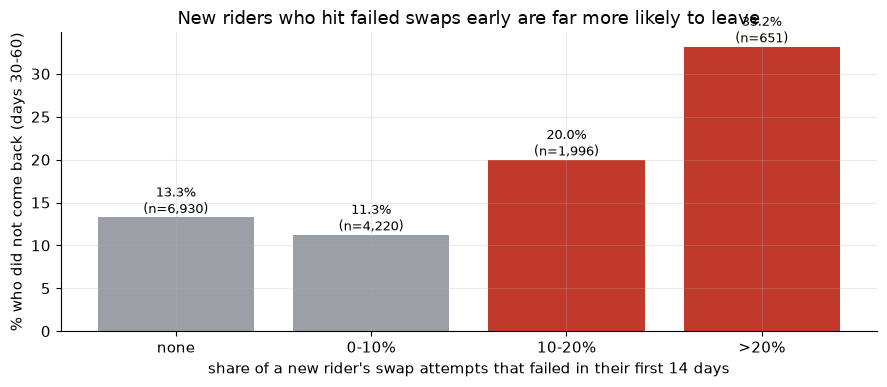

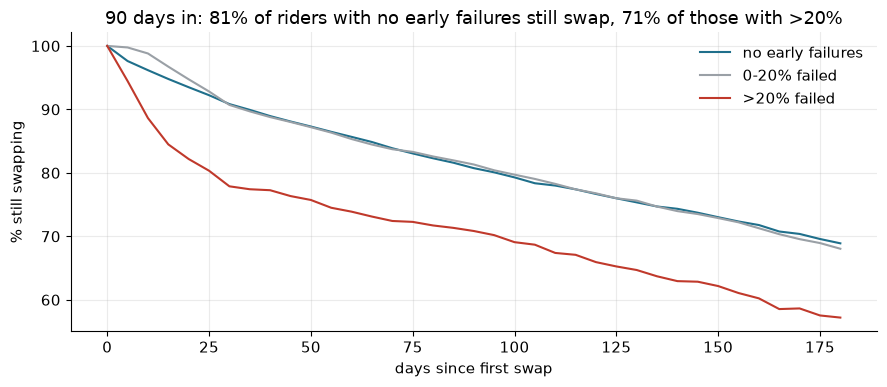

Churn model fitted on 2024 starters: AUC 0.680 in sample, 0.651 on 4,154 riders who started in 2025; early-failure odds ratio 1.42 in the 2024-only fit
                size   mean
segment                    
bike_taxi        661  0.151
cargo_3w         856  0.159
ecom_logistics  1903  0.143
food_delivery   3046  0.154
independent     5338  0.131
quick_commerce  1993  0.166


/Users/kinnu/projects/gradient-analytics/.venv/lib/python3.12/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


13.113525665043088

In [12]:
nr = sql("""
with fa as (select rider_id, min(ts) t0 from evr group by 1),
w as (select e.rider_id, count(*) att, avg((not ok)::int) frate, avg(queue_wait_sec)/60 qw,
        avg((b.supplier='Kyron')::int) kyr, mode(e.city) city, mode(e.gen) gen
      from evr e join fa using(rider_id) left join raw_batteries b on b.battery_id=e.battery_out_id
      where e.ts < fa.t0 + interval 14 day group by 1),
lat as (select e.rider_id, count(*) later from evr e join fa using(rider_id)
        where e.ts between fa.t0 + interval 30 day and fa.t0 + interval 60 day group by 1)
select r.rider_id, r.plan_type, r.vehicle_class, r.signup_channel, coalesce(p.partner_segment,'independent') segment,
  fa.t0, month(fa.t0) in (4,5,6) summer_start, w.*, coalesce(lat.later,0)=0 churn
from raw_riders r join fa using(rider_id) join w using(rider_id) left join lat using(rider_id) left join raw_fleet_partners p using(partner_id)
where r.signup_date >= '2024-01-01' and fa.t0 < '2025-05-01'""")
nr["churn"] = nr.churn.astype(int); nr["summer_start"] = nr.summer_start.astype(int)
nr["kyr_missing"] = nr.kyr.isna().astype(int)  # riders with no completed swap in 14 days received no pack: keep them, flag them
nr["frate10"] = 10*nr.frate; nr["kyr10"] = 10*nr.kyr.fillna(0); nr["att_c"] = nr.att.clip(upper=40)
fact("churn_no_completed_riders", nr.kyr_missing.sum())
fact("new_riders", len(nr)); fact("new_rider_churn_pct", 100*nr.churn.mean())
coh = nr.groupby(pd.to_datetime(nr.t0).dt.to_period("Q").astype(str)).churn.agg(["size", "mean"])
print(coh.round(3).to_string())
fact("churn_summer_start_pct", 100*nr[nr.summer_start == 1].churn.mean()); fact("churn_other_start_pct", 100*nr[nr.summer_start == 0].churn.mean())
bands = pd.cut(nr.frate, [-.001, 0, .1, .2, 1], labels=["none", "0-10%", "10-20%", ">20%"])
fb = nr.groupby(bands).churn.agg(["size", "mean"]); print(fb.round(3).to_string())
fact("churn_nofail_pct", 100*fb.loc["none", "mean"]); fact("churn_nofail_n", fb.loc["none", "size"])
fact("churn_highfail_pct", 100*fb.loc[">20%", "mean"]); fact("churn_highfail_n", fb.loc[">20%", "size"])

logit = smf.logit("churn ~ frate10 + qw + kyr10 + kyr_missing + att_c + summer_start + C(city) + C(plan_type) + C(vehicle_class) + C(signup_channel)", nr).fit(disp=0)
fact("churn_model_n", logit.nobs)
tab = pd.DataFrame({"odds_ratio": np.exp(logit.params), "p": logit.pvalues}).round(3)
print(tab.to_string())
fact("or_frate10", np.exp(logit.params["frate10"])); fact("or_kyr10", np.exp(logit.params["kyr10"])); fact("or_summer", np.exp(logit.params["summer_start"]))
fact("p_kyr10", logit.pvalues["kyr10"]); fact("p_qw", logit.pvalues["qw"])
# Churned riders attributable to early failures: predicted churn as observed minus predicted churn with zero early failures
cf = nr.copy(); cf["frate10"] = 0
excess_fail = float((logit.predict(nr) - logit.predict(cf)).sum())
cf2 = nr.copy(); cf2["kyr10"] = 0
excess_kyr = float((logit.predict(nr) - logit.predict(cf2)).sum())
cf3 = nr.copy(); cf3["summer_start"] = 0
excess_summer = float((logit.predict(nr) - logit.predict(cf3)).sum())
cf4 = nr.copy(); cf4.loc[cf4.plan_type == "partner_billed", "plan_type"] = "pay_as_you_go"
excess_plan = float((logit.predict(nr) - logit.predict(cf4)).sum())
churned = nr.churn.sum()
fact("churned_new_riders", churned); fact("churn_from_early_fail", excess_fail); fact("churn_from_early_fail_pct", 100*excess_fail/churned)
fact("churn_from_kyron", excess_kyr); fact("churn_from_kyron_pct", 100*excess_kyr/churned); fact("churn_from_summer_start_pct", 100*excess_summer/churned); fact("churn_from_partner_plan_pct", 100*excess_plan/churned)
fact("or_partner_plan", 1/np.exp(logit.params["C(plan_type)[T.pay_as_you_go]"]))
drivers = pd.DataFrame([
    ("Failed swaps in the first 14 days", np.exp(logit.params["frate10"]), logit.pvalues["frate10"], excess_fail),
    ("Kyron share of packs received", np.exp(logit.params["kyr10"]), logit.pvalues["kyr10"], excess_kyr),
    ("Starting in April-June", np.exp(logit.params["summer_start"]), logit.pvalues["summer_start"], excess_summer),
    ("Partner-billed plan (vs paying themselves)", 1/np.exp(logit.params["C(plan_type)[T.pay_as_you_go]"]), logit.pvalues["C(plan_type)[T.pay_as_you_go]"], excess_plan),
], columns=["factor", "odds ratio (per 10 pts / yes)", "p", "churned riders it accounts for"])
drivers["share of churn %"] = 100*drivers.iloc[:, 3]/churned
drivers["label"] = np.where((drivers.p < 0.05) & (drivers["share of churn %"] >= 10), "primary", np.where(drivers.p < 0.05, "secondary", "not shown"))
print(drivers.round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(fb.index.astype(str), 100*fb["mean"], color=[MUTED, MUTED, ACCENT, ACCENT])
for p_, n_ in zip(ax.patches, fb["size"]): ax.annotate(f"{p_.get_height():.1f}%\n(n={n_:,})", (p_.get_x()+p_.get_width()/2, p_.get_height()), ha="center", va="bottom", fontsize=9)
ax.set_xlabel("share of a new rider's swap attempts that failed in their first 14 days"); ax.set_ylabel("% who did not come back (days 30-60)")
ax.set_title("New riders who hit failed swaps early are far more likely to leave")
savefig(fig, "q6_churn")

# Survival view: share of new riders still active N days after their first swap (active = any attempt on or after day N),
# by early failure group; riders whose window runs past the end of the data are counted only where observable.
lastseen = sql("""with fa as (select rider_id, min(ts) t0, max(ts) t1 from evr group by 1) select rider_id, date_diff('day', t0, t1) life, date_diff('day', t0, timestamp '2025-06-30 23:59:59') obs from fa""")
sv = nr[["rider_id", "frate"]].merge(lastseen, on="rider_id")
sv["grp"] = pd.cut(sv.frate, [-.001, 0, .2, 1], labels=["no early failures", "0-20% failed", ">20% failed"])
days = np.arange(0, 181, 5); curves = {}
for gname, g in sv.groupby("grp"):
    curves[gname] = [100*(g[g.obs >= d_].life >= d_).mean() for d_ in days]
fact("surv90_nofail_pct", curves["no early failures"][list(days).index(90)]); fact("surv90_highfail_pct", curves[">20% failed"][list(days).index(90)])
fig, ax = plt.subplots(figsize=(9, 4))
for gname, col in [("no early failures", GOOD), ("0-20% failed", MUTED), (">20% failed", ACCENT)]:
    ax.plot(days, curves[gname], color=col, label=gname)
ax.set_xlabel("days since first swap"); ax.set_ylabel("% still swapping"); ax.legend(frameon=False)
ax.set_title(f"90 days in: {FACTS['surv90_nofail_pct']:.0f}% of riders with no early failures still swap, {FACTS['surv90_highfail_pct']:.0f}% of those with >20%")
savefig(fig, "q6_survival")

# Out-of-sample check: fit on riders who started before 2025, predict riders who started in 2025
from sklearn.metrics import roc_auc_score
nr_m = nr  # riders with no completed swap in 14 days have no pack supplier share; the model drops them too
train = nr_m[pd.to_datetime(nr_m.t0) < "2025-01-01"]; test = nr_m[pd.to_datetime(nr_m.t0) >= "2025-01-01"]
f_ = "churn ~ frate10 + qw + kyr10 + kyr_missing + att_c + summer_start + C(city) + C(plan_type) + C(vehicle_class) + C(signup_channel)"
m_tr = smf.logit(f_, train).fit(disp=0)
auc_out = roc_auc_score(test.churn, m_tr.predict(test)); auc_in = roc_auc_score(train.churn, m_tr.predict(train))
fact("churn_auc_in", auc_in); fact("churn_auc_out", auc_out); fact("churn_test_riders", len(test))
fact("or_frate10_train", np.exp(m_tr.params["frate10"]))
print(f"Churn model fitted on 2024 starters: AUC {auc_in:.3f} in sample, {auc_out:.3f} on {len(test):,} riders who started in 2025; early-failure odds ratio {np.exp(m_tr.params['frate10']):.2f} in the 2024-only fit")
by_partner = nr.groupby("segment").churn.agg(["size", "mean"])
print(by_partner.round(3).to_string())
fact("churn_independent_pct", 100*by_partner.loc["independent", "mean"])

### How sure are the headline gaps? Bootstrap confidence intervals
Stations (or riders) are resampled with replacement 1,000 times, so the intervals respect that attempts at the same station are not independent.

In [13]:
rng_ = np.random.default_rng(59500)
st_s = sql("""select station_id, gen, city, sum((not ok)::int) filter (where summer) fs, count(*) filter (where summer) ns,
   sum((not ok)::int) filter (where not summer) fo, count(*) filter (where not summer) no_ from evr group by all order by station_id""")
def gap(d):
    g1 = d[d.gen == "Gen1"]; g3 = d[d.gen == "Gen3"]
    return 100*(g1.fs.sum()/g1.ns.sum() - g3.fs.sum()/g3.ns.sum())
boot = [gap(st_s.iloc[rng_.integers(0, len(st_s), len(st_s))]) for _ in range(1000)]
fact("ci_gen1_gen3_gap", gap(st_s)); fact("ci_gen1_gen3_gap_lo", np.percentile(boot, 2.5)); fact("ci_gen1_gen3_gap_hi", np.percentile(boot, 97.5))
nr_sorted = nr.sort_values("rider_id")  # fixed row order so the seeded bootstrap is reproducible
hi_ = nr_sorted[nr_sorted.frate > .2].churn.values; no_ = nr_sorted[nr_sorted.frate == 0].churn.values
bc = [100*(rng_.choice(hi_, len(hi_)).mean() - rng_.choice(no_, len(no_)).mean()) for _ in range(1000)]
fact("ci_churn_gap", 100*(hi_.mean() - no_.mean())); fact("ci_churn_gap_lo", np.percentile(bc, 2.5)); fact("ci_churn_gap_hi", np.percentile(bc, 97.5))
kb = sql("select supplier, soh_loss_per_swap from batt where pack_type like '2W%' and soh_loss_per_swap is not null order by battery_id")
ky_ = kb[kb.supplier == "Kyron"].soh_loss_per_swap.values; ot_ = kb[kb.supplier != "Kyron"].soh_loss_per_swap.values
bk = [rng_.choice(ky_, len(ky_)).mean()/rng_.choice(ot_, len(ot_)).mean() for _ in range(1000)]
fact("ci_kyron_ratio", ky_.mean()/ot_.mean()); fact("ci_kyron_ratio_lo", np.percentile(bk, 2.5)); fact("ci_kyron_ratio_hi", np.percentile(bk, 97.5))
ci = pd.DataFrame([
    ("Gen1 minus Gen3 summer failure rate (points)", FACTS["ci_gen1_gen3_gap"], FACTS["ci_gen1_gen3_gap_lo"], FACTS["ci_gen1_gen3_gap_hi"]),
    ("Churn, >20% early failures minus none (points)", FACTS["ci_churn_gap"], FACTS["ci_churn_gap_lo"], FACTS["ci_churn_gap_hi"]),
    ("Kyron 2W health loss per swap, times other 2W packs", FACTS["ci_kyron_ratio"], FACTS["ci_kyron_ratio_lo"], FACTS["ci_kyron_ratio_hi"]),
], columns=["gap", "estimate", "95% low", "95% high"])
print(ci.round(2).to_string(index=False))

                                                gap  estimate  95% low  95% high
       Gen1 minus Gen3 summer failure rate (points)      7.79     6.31      9.07
     Churn, >20% early failures minus none (points)     19.90    16.34     23.74
Kyron 2W health loss per swap, times other 2W packs      3.22     3.21      3.24


## 9. The chain, priced: what summer failures at old cabinets cost
Three links, each measured separately:
1. **Extra failed attempts**: Gen1 attempts in April-June beyond what Gen1 fails the rest of the year.
2. **Swaps lost for good**: the share of failed attempts where the rider did not complete a swap anywhere in the next two hours, priced at average revenue per swap.
3. **Riders lost**: new riders the churn model attributes to early failed swaps, priced at the monthly revenue of a retained new rider for 6 months (**ASSUMPTION**; 3 and 12 months shown as the range).

                                                             link   size                                       ₹
          Extra failed attempts at Gen1 in Apr-Jun (both summers) 52,987                                        
     ... of which the rider did not swap anywhere within 24 hours    44%              ₹15.0 lakh revenue at risk
New riders lost to early failures that happened at Gen1 in summer     98 ₹4.8-19.4 lakh (3-12 months of revenue)
                                                         leak  ₹ lakh
          Summer failures at Gen1: new riders lost (6 months)     9.7
Summer failures at Gen1: revenue at risk (no swap within 24h)    15.0
       ZipDrop discount raised 12% -> 28% (Nov 2024-Jun 2025)    39.6
                 Kyron packs wearing out faster (to Jun 2025)   434.6


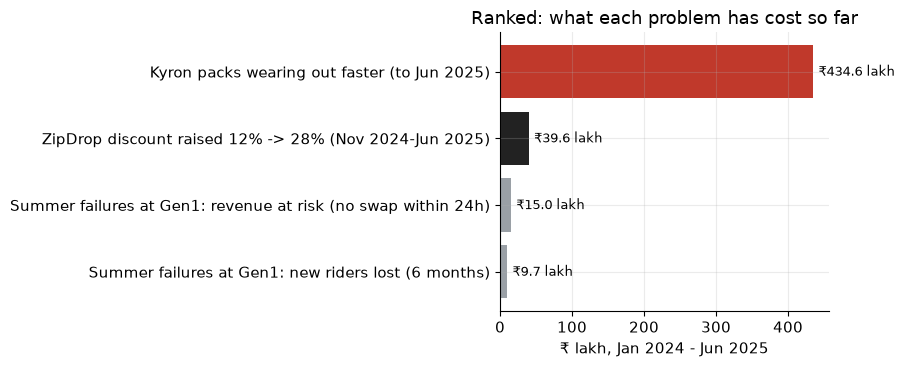

In [14]:
g1 = sql("""select summer, count(*) n, 1-avg(ok::int) f from evr where gen='Gen1' group by 1""").set_index("summer")
excess_attempts = g1.loc[True, "n"] * (g1.loc[True, "f"] - g1.loc[False, "f"])
fact("gen1_summer_excess_failed", excess_attempts)
rec = sql("""with f as (select rider_id, ts from evr where not ok),
 nxt as (select f.rider_id, f.ts, min(e.ts) nxt from f left join evr e on e.rider_id=f.rider_id and e.ok and e.ts > f.ts and e.ts <= f.ts + interval 2 hour group by all)
 select avg((nxt is null)::int) lost from nxt""").lost[0]
fact("failed_not_recovered_pct", 100*rec)
rec24 = sql("""with f as (select rider_id, ts from evr where not ok),
 nxt as (select f.rider_id, f.ts, min(e.ts) nxt from f left join evr e on e.rider_id=f.rider_id and e.ok and e.ts > f.ts and e.ts <= f.ts + interval 24 hour group by all)
 select avg((nxt is null)::int) lost from nxt""").lost[0]
fact("failed_not_recovered_24h_pct", 100*rec24)
avg_rev = sql("select avg(revenue) r from evr where ok").r[0]
lost_swaps = excess_attempts * rec24  # not recovered anywhere within 24 hours
fact("gen1_summer_lost_swaps", lost_swaps); fact("gen1_summer_lost_rev_lakh", lost_swaps*avg_rev/1e5)
# churn link: riders lost to early failures, and how many of their early failures happened at Gen1 in summer
share_gen1_summer = sql("""with fa as (select rider_id, min(ts) t0 from evr group by 1)
  select avg((e.gen='Gen1' and e.summer)::int) v from evr e join fa using(rider_id) where not e.ok and e.ts < fa.t0 + interval 14 day""").v[0]
fact("early_fail_share_gen1_summer_pct", 100*share_gen1_summer)
monthly_rev_retained = sql("""with fa as (select rider_id, min(ts) t0 from evr group by 1)
  select sum(e.revenue) / count(distinct e.rider_id) / 1.0 r from evr e join fa using(rider_id)
  where e.ts between fa.t0 + interval 30 day and fa.t0 + interval 60 day""").r[0]
fact("monthly_rev_retained_rider", monthly_rev_retained)
riders_lost = excess_fail * share_gen1_summer
fact("riders_lost_gen1_summer", riders_lost)
for mths in (3, 6, 12):
    fact(f"riders_lost_value_{mths}m_lakh", riders_lost*monthly_rev_retained*mths/1e5)
chain = pd.DataFrame([
    ("Extra failed attempts at Gen1 in Apr-Jun (both summers)", f"{excess_attempts:,.0f}", ""),
    ("... of which the rider did not swap anywhere within 24 hours", f"{100*rec24:.0f}%", f"₹{lost_swaps*avg_rev/1e5:.1f} lakh revenue at risk"),
    ("New riders lost to early failures that happened at Gen1 in summer", f"{riders_lost:,.0f}", f"₹{FACTS['riders_lost_value_3m_lakh']:.1f}-{FACTS['riders_lost_value_12m_lakh']:.1f} lakh (3-12 months of revenue)"),
], columns=["link", "size", "₹"])
print(chain.to_string(index=False))

leaks = pd.DataFrame([
    ("Kyron packs wearing out faster (to Jun 2025)", FACTS["kyron_excess_wear_inr"]/1e5),
    ("ZipDrop discount raised 12% -> 28% (Nov 2024-Jun 2025)", FACTS["zipdrop_amendment_cost_did_lakh"]),
    ("Summer failures at Gen1: revenue at risk (no swap within 24h)", FACTS["gen1_summer_lost_rev_lakh"]),
    ("Summer failures at Gen1: new riders lost (6 months)", FACTS["riders_lost_value_6m_lakh"]),
], columns=["leak", "₹ lakh"]).sort_values("₹ lakh")
print(leaks.round(1).to_string(index=False))
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(leaks.leak, leaks["₹ lakh"], color=[ACCENT if "Kyron" in l else (INK if "ZipDrop" in l else MUTED) for l in leaks.leak])
for p_ in ax.patches: ax.annotate(f"₹{p_.get_width():.1f} lakh", (p_.get_width(), p_.get_y()+p_.get_height()/2), va="center", xytext=(4, 0), textcoords="offset points", fontsize=9)
ax.set_xlabel("₹ lakh, Jan 2024 - Jun 2025"); ax.set_title("Ranked: what each problem has cost so far")
savefig(fig, "chain_leaks")

## 10. Next April: which stations will fail next summer, tested on a summer the rule never saw
**Back-test.** Take one simple rule from summer 2024 alone: a station's expected summer failure rate is the 2024 rate of its *charger generation in its city* (for example, Gen1 in Jaipur). Freeze it and compare with what each station actually did in summer 2025. Then ask whether a station's *own* 2024 history adds anything beyond its group.

Out-of-sample R^2 (1 - SSE/SST): rule, leave-one-station-out 0.990; each station's own 2024 rate 0.985; network average -0.003


Group rule from 2024 predicts each station's 2025 summer failure rate: R^2 0.991, mean error 0.38 points (90 stations)
A station's own 2024 history beyond its group: rank correlation 0.13 -> adds nothing
                                      stations  fails24     n24  fails25     n25    f24    f25  share_fail25  share_att25
cohort                                                                                                                   
Gen1 in Jaipur, Delhi NCR, Hyderabad        36  27472.0  172800  41875.0  267903  0.159  0.156         0.512        0.274
all other stations                         114  14137.0  245260  39859.0  710036  0.058  0.056         0.488        0.726


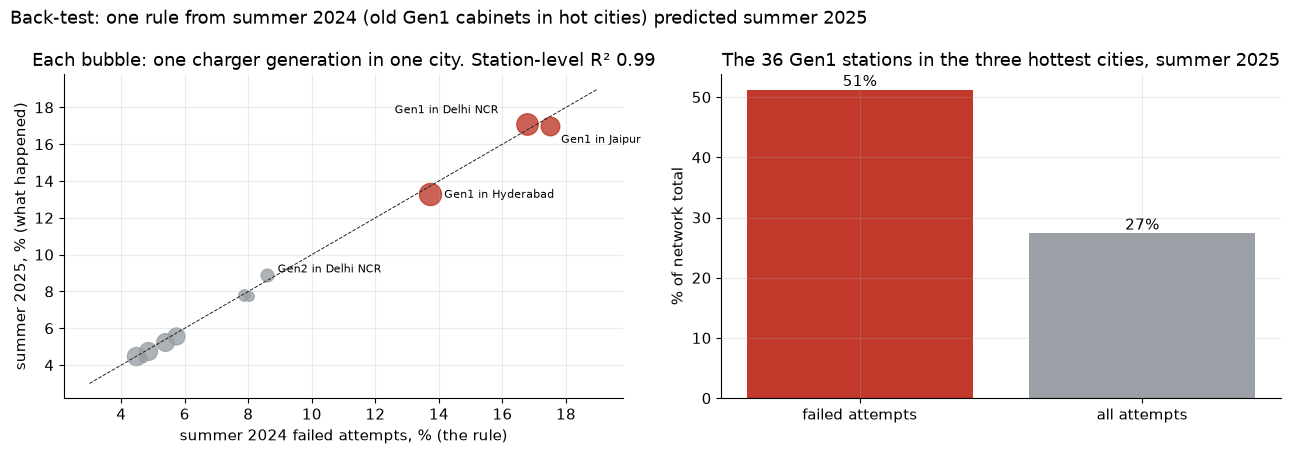

In [15]:
ss = sql("""select station_id, city, gen, wave,
  1-avg(ok::int) filter (where y=2024 and summer) f24, count(*) filter (where y=2024 and summer) n24,
  1-avg(ok::int) filter (where y=2025 and summer) f25, count(*) filter (where y=2025 and summer) n25,
  sum((not ok)::int) filter (where y=2024 and summer) fails24,
  sum((not ok)::int) filter (where y=2025 and summer) fails25,
  count(distinct rider_id) filter (where y=2025 and summer) riders25
  from evr group by all""")
ss["group"] = ss.gen + " in " + ss.city
both = ss.dropna(subset=["f24", "f25"]).copy()
g24 = both.groupby("group").apply(lambda d: d.fails24.sum()/d.n24.sum()).rename("group24")
both = both.join(g24, on="group")
r_rule = stats.pearsonr(both.group24, both.f25)[0]
mae_rule = (both.group24 - both.f25).abs().mean()
rho = stats.spearmanr(both.f24, both.f25).correlation
gsum = both.groupby("group")[["fails24", "n24"]].transform("sum")
both["group24_loo"] = np.where(gsum.n24 > both.n24, (gsum.fails24 - both.fails24)/(gsum.n24 - both.n24), both.f24)
def oos_r2(pred): return 1 - ((both.f25 - pred)**2).sum()/((both.f25 - both.f25.mean())**2).sum()
net24 = both.fails24.sum()/both.n24.sum()
fact("oos_r2_rule_loo", oos_r2(both.group24_loo)); fact("oos_r2_network_mean", oos_r2(pd.Series(net24, index=both.index)))
fact("oos_r2_own_last_year", oos_r2(both.f24)); fact("rmse_rule_loo_pts", 100*np.sqrt(((both.f25 - both.group24_loo)**2).mean()))
fact("stations_total", len(ss))
print(f"Out-of-sample R^2 (1 - SSE/SST): rule, leave-one-station-out {FACTS['oos_r2_rule_loo']:.3f}; each station's own 2024 rate {FACTS['oos_r2_own_last_year']:.3f}; network average {FACTS['oos_r2_network_mean']:.3f}")
both["own_vs_group24"] = both.f24 - both.group24
both["own_vs_group25"] = both.f25 - both.groupby("group").f25.transform("mean")
rho_within = stats.spearmanr(both.own_vs_group24, both.own_vs_group25).correlation
fact("backtest_stations", len(both)); fact("backtest_spearman", rho)
fact("rule_r2", r_rule**2); fact("rule_mae_pts", 100*mae_rule); fact("within_group_spearman", rho_within)
_r = np.random.default_rng(1); _b = both.sort_values("station_id").reset_index(drop=True)
_bs = [stats.spearmanr(*_b.iloc[_r.integers(0, len(_b), len(_b))][["own_vs_group24", "own_vs_group25"]].values.T).correlation for _ in range(1000)]
fact("within_group_spearman_lo", np.percentile(_bs, 2.5)); fact("within_group_spearman_hi", np.percentile(_bs, 97.5))
print(f"Group rule from 2024 predicts each station's 2025 summer failure rate: R^2 {r_rule**2:.3f}, mean error {100*mae_rule:.2f} points ({len(both)} stations)")
print(f"A station's own 2024 history beyond its group: rank correlation {rho_within:.2f} -> adds nothing")

HOT = ["Jaipur", "Delhi NCR", "Hyderabad"]
ss["cohort"] = np.where((ss.gen == "Gen1") & ss.city.isin(HOT), "Gen1 in Jaipur, Delhi NCR, Hyderabad", "all other stations")
co = ss.groupby("cohort").agg(stations=("station_id", "size"), fails24=("fails24", "sum"), n24=("n24", "sum"), fails25=("fails25", "sum"), n25=("n25", "sum"))
co["f24"] = co.fails24/co.n24; co["f25"] = co.fails25/co.n25
co["share_fail25"] = co.fails25/co.fails25.sum(); co["share_att25"] = co.n25/co.n25.sum()
print(co.round(3).to_string())
hc = co.loc["Gen1 in Jaipur, Delhi NCR, Hyderabad"]
fact("hot_gen1_stations", hc.stations); fact("hot_gen1_fail24_pct", 100*hc.f24); fact("hot_gen1_fail25_pct", 100*hc.f25)
fact("hot_gen1_share_fail25_pct", 100*hc.share_fail25); fact("hot_gen1_share_att25_pct", 100*hc.share_att25)
fact("hot_gen1_attempts_s24", hc.n24); fact("hot_gen1_attempts_s25", hc.n25)
oc = co.loc["all other stations"]; fact("other_stations_fail25_pct", 100*oc.f25); fact("other_stations_n", oc.stations)
new = ss[ss.f24.isna() & ss.f25.notna()]
fact("new_stations_2025", len(new)); fact("new_stations_fail_2025_pct", 100*new.fails25.sum()/new.n25.sum())

grp = both.groupby("group").agg(n=("n25", "sum"), g24=("group24", "first"), f25=("fails25", "sum"), n25=("n25", "sum"))
grp["g25"] = grp.f25/grp.n25
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for gname, r in grp.iterrows():
    hot = gname.startswith("Gen1") and any(c in gname for c in HOT)
    axes[0].scatter(100*r.g24, 100*r.g25, s=r.n/400, color=ACCENT if hot else MUTED, alpha=.8)
    OFF = {"Gen1 in Delhi NCR": (-95, 8), "Gen1 in Jaipur": (8, -12), "Gen1 in Hyderabad": (10, -3), "Gen2 in Delhi NCR": (8, 2)}
    if gname in OFF: axes[0].annotate(gname, (100*r.g24, 100*r.g25), xytext=OFF[gname], textcoords="offset points", fontsize=8)
lim = [3, 19]; axes[0].plot(lim, lim, color=INK, lw=.7, ls="--")
axes[0].set_xlabel("summer 2024 failed attempts, % (the rule)"); axes[0].set_ylabel("summer 2025, % (what happened)")
axes[0].set_title(f"Each bubble: one charger generation in one city. Station-level R² {r_rule**2:.2f}")
bars = pd.DataFrame({"share of summer-2025 failed attempts": [100*hc.share_fail25], "share of summer-2025 attempts": [100*hc.share_att25]})
axes[1].bar(["failed attempts", "all attempts"], [100*hc.share_fail25, 100*hc.share_att25], color=[ACCENT, MUTED])
for p_ in axes[1].patches: axes[1].annotate(f"{p_.get_height():.0f}%", (p_.get_x()+p_.get_width()/2, p_.get_height()), ha="center", va="bottom")
axes[1].set_title(f"The {int(hc.stations)} Gen1 stations in the three hottest cities, summer 2025"); axes[1].set_ylabel("% of network total")
fig.suptitle("Back-test: one rule from summer 2024 (old Gen1 cabinets in hot cities) predicted summer 2025", x=0.01, ha="left")
savefig(fig, "backtest")

### The April 2026 list
Because a station's own history adds nothing beyond its group, the list is the whole group, not a ranking within it. **Wave 1:** every Gen1 station in Jaipur and Delhi NCR (the two groups failing on about 17% of summer attempts). **Wave 2:** Gen1 in Hyderabad. "Excess failed attempts" = attempts beyond each station's own rate outside summer, at the summer-2025 volume.

In [16]:
base = sql("select station_id, 1-avg(ok::int) f_other from evr where not summer group by 1")
l26 = ss.merge(base, on="station_id").dropna(subset=["f25"])
l26["excess_failed"] = l26.n25*(l26.f25 - l26.f_other)
l26 = l26[(l26.gen == "Gen1") & l26.city.isin(HOT)].copy()
l26["wave_2026"] = np.where(l26.city.isin(["Jaipur", "Delhi NCR"]), 1, 2)
l26 = l26.sort_values(["wave_2026", "city", "station_id"])
april = l26[["wave_2026", "station_id", "city", "gen", "f24", "f25", "f_other", "n25", "excess_failed", "riders25"]]
april.to_csv(os.path.join(OUT, "april_2026_list.csv"), index=False)
for _, r in april.iterrows(): fact(f"station_fail25_{r.station_id}", 100*r.f25)
wv = april.groupby("wave_2026").agg(stations=("station_id", "size"), excess=("excess_failed", "sum"), riders=("riders25", "sum"),
                                     f25=("f25", "mean"))
print(wv.round(1).to_string())
for w_, r in wv.iterrows():
    fact(f"wave{w_}_stations", r.stations); fact(f"wave{w_}_excess_failed", r.excess); fact(f"wave{w_}_riders", r.riders)
fact("list_excess_failed", april.excess_failed.sum()); fact("list_riders_exposed", april.riders25.sum()); fact("list_stations", len(april))
# Effect of the upgrade, from the data: if each listed Gen1 station had failed at the summer-2025 rate of Gen3 stations in its own city
g3 = ss[ss.gen == "Gen3"].groupby("city").apply(lambda d: d.fails25.sum()/d.n25.sum()).rename("g3_rate")
up = april.merge(g3, left_on="city", right_index=True)
up["avoided"] = up.n25*(up.f25 - up.g3_rate)
for w_, d_ in up.groupby("wave_2026"): fact(f"wave{w_}_avoided_failed", d_.avoided.sum())
fact("upgrade_avoided_failed", up.avoided.sum()); fact("upgrade_avoided_pct_of_summer_fails", 100*up.avoided.sum()/ss.fails25.sum())
fact("upgrade_cohort_fail_after_pct", 100*((up.n25*up.f25).sum() - up.avoided.sum())/up.n25.sum())
print(f"If the 36 Gen1 stations failed like Gen3 in their cities: {up.avoided.sum():,.0f} fewer failed attempts in summer 2025 ({FACTS['upgrade_avoided_pct_of_summer_fails']:.1f}% of all summer failures)")
pune_g1 = ss[(ss.gen == "Gen1") & (ss.city == "Pune")]
fact("pune_gen1_stations", len(pune_g1)); fact("pune_gen1_fail25_pct", 100*pune_g1.fails25.sum()/pune_g1.n25.sum())
print(april.assign(f24=lambda d: (100*d.f24).round(1), f25=lambda d: (100*d.f25).round(1), f_other=lambda d: (100*d.f_other).round(1),
                   excess_failed=lambda d: d.excess_failed.round(0)).to_string(index=False))

           stations   excess  riders  f25
wave_2026                                
1                23  21265.1   21323  0.2
2                13   9086.4   12546  0.1
If the 36 Gen1 stations failed like Gen3 in their cities: 27,193 fewer failed attempts in summer 2025 (33.3% of all summer failures)
 wave_2026  station_id      city  gen  f24  f25  f_other   n25  excess_failed  riders25
         1 STN-DEL-033 Delhi NCR Gen1 15.9 17.3      4.0  6617          880.0       991
         1 STN-DEL-035 Delhi NCR Gen1 16.6 17.3      4.2  5908          779.0      1015
         1 STN-DEL-036 Delhi NCR Gen1 17.4 17.1      4.2  8038         1032.0      1037
         1 STN-DEL-037 Delhi NCR Gen1 17.3 16.9      4.6  6997          860.0      1059
         1 STN-DEL-038 Delhi NCR Gen1 15.7 16.9      4.1  4685          603.0       996
         1 STN-DEL-039 Delhi NCR Gen1 16.7 17.2      4.5  6041          768.0       723
         1 STN-DEL-040 Delhi NCR Gen1 15.5 17.0      4.5  8722         1094.0      

### Did the expansion waves go where riders needed them?

     city  fails_s24  new_stations  share_need  share_new
   Jaipur     9401.0             8        22.6       13.3
   Mumbai     2703.0             9         6.5       15.0
Hyderabad     9650.0            10        23.2       16.7
     Pune     4087.0             9         9.8       15.0
Delhi NCR    11439.0            12        27.5       20.0
Bengaluru     4329.0            12        10.4       20.0
wave               Launch  Wave1_2024H2  Wave2_2025H1
location_type                                        
commercial_hub         39             1             4
highway_fuel_pump       2            14             5
market                 33             0            14
residential             6            13             2
tech_park               5             1             1
transit_hub             5             1             4
       stations  growth    f25
near                          
False        24   0.525  0.153
True         12   0.559  0.164


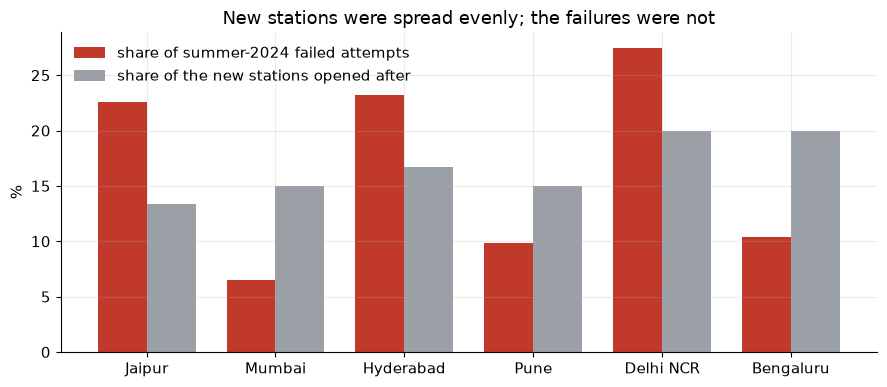

In [17]:
need = sql("""select city, sum((not ok)::int) filter (where y=2024 and summer) fails_s24 from evr group by 1""")
waves = sql("select city, count(*) filter (where expansion_wave<>'Launch') new_stations from st group by 1")
need = need.merge(waves, on="city"); need["share_need"] = 100*need.fails_s24/need.fails_s24.sum(); need["share_new"] = 100*need.new_stations/need.new_stations.sum()
print(need.round(1).to_string(index=False))
for _, r in need.iterrows(): fact(f"share_need_{r.city.replace(' ','_')}_pct", r.share_need); fact(f"share_new_{r.city.replace(' ','_')}_pct", r.share_new)
fact("new_stations_total", need.new_stations.sum())
hot3 = need.city.isin(HOT)
fact("hot3_share_need_pct", need[hot3].share_need.sum()); fact("hot3_share_new_pct", need[hot3].share_new.sum())
# Where the waves went: location type, use, and whether a nearby new station relieved a hot Gen1 station
loc = sql("select expansion_wave wave, location_type, count(*) n from st group by all").pivot(index="location_type", columns="wave", values="n").fillna(0).astype(int)
print(loc.to_string())
fact("wave1_easy_sites", loc.loc[["highway_fuel_pump", "residential"], "Wave1_2024H2"].sum()); fact("wave1_stations", loc["Wave1_2024H2"].sum())
fact("wave2_market_sites", loc.loc["market", "Wave2_2025H1"]); fact("wave2_stations", loc["Wave2_2025H1"].sum())
use = sql("""select wave, count(*) filter (where ok) / count(distinct station_id) / count(distinct ts::date) per_day from evr where ts >= '2025-03-01' group by 1""").set_index("wave").per_day
for w_, v in use.items(): fact(f"swaps_per_station_day_{w_}", v)
geo = sql("select station_id, city, charger_generation gen, expansion_wave wave, latitude la, longitude lo from st")
def _km(a, b, c, d):
    return 6371*2*np.arcsin(np.sqrt(np.sin(np.radians(c - a)/2)**2 + np.cos(np.radians(a))*np.cos(np.radians(c))*np.sin(np.radians(d - b)/2)**2))
newg = geo[geo.wave != "Launch"]; hotg = geo[(geo.gen == "Gen1") & geo.city.isin(HOT)].copy()
hotg["near_km"] = [min(_km(r.la, r.lo, n.la, n.lo) for n in newg[newg.city == r.city].itertuples()) for r in hotg.itertuples()]
gr = ss.set_index("station_id")[["n24", "n25", "f24", "f25"]].join(hotg.set_index("station_id").near_km, how="inner")
gr["growth"] = gr.n25/gr.n24 - 1; gr["near"] = gr.near_km <= 1.0
rel_ = gr.groupby("near").agg(stations=("growth", "size"), growth=("growth", "mean"), f25=("f25", "mean"))
print(rel_.round(3).to_string())
fact("hot_gen1_near_new_median_km", hotg.near_km.median())
fact("hot_gen1_growth_near_pct", 100*rel_.loc[True, "growth"]); fact("hot_gen1_growth_far_pct", 100*rel_.loc[False, "growth"])
fact("hot_gen1_fail25_near_pct", 100*rel_.loc[True, "f25"]); fact("hot_gen1_fail25_far_pct", 100*rel_.loc[False, "f25"])
fact("hot_gen1_near_count", rel_.loc[True, "stations"])

fig, ax = plt.subplots(figsize=(9, 4))
xx = np.arange(len(need)); wdt = .38
ax.bar(xx - wdt/2, need.share_need, wdt, color=ACCENT, label="share of summer-2024 failed attempts")
ax.bar(xx + wdt/2, need.share_new, wdt, color=MUTED, label="share of the new stations opened after")
ax.set_xticks(xx, need.city); ax.set_ylabel("%"); ax.legend(frameon=False)
ax.set_title("New stations were spread evenly; the failures were not")
savefig(fig, "expansion")

### Anomalies
Stations that behave unlike their own group (charger generation in a city) on failures, system errors, queue time or abandonment, and pack or data irregularities worth flagging.

In [18]:
an = sql("""select station_id, city, gen, avg((not ok)::int) f, avg((event_type='failed_system_error')::int) se, avg(queue_wait_sec) q, avg((event_type='abandoned_queue')::int) ab
   from evr group by all""")
for c in ["f", "se", "q", "ab"]:
    an[c + "_z"] = an.groupby(["gen", "city"])[c].transform(lambda x: (x - x.mean())/x.std(ddof=0))
outl = an[(an[["f_z", "se_z", "q_z", "ab_z"]].abs() > 3).any(axis=1)]
fact("station_outliers_3sd", len(outl))
kh = sql("""select city in ('Jaipur','Delhi NCR','Hyderabad') hot, avg(soh_in_pct) soh from evr e join raw_batteries b on b.battery_id=e.battery_in_id
   where b.supplier='Kyron' and e.y=2025 group by 1""").set_index("hot").soh
fact("kyron_soh_in_hot_2025", kh[True]); fact("kyron_soh_in_cool_2025", kh[False])
print(f"Stations more than 3 SD from their group on any service measure: {len(outl)}")
print(f"Kyron packs returned in 2025 at {kh[True]:.1f}% health in the three hot cities vs {kh[False]:.1f}% elsewhere")
anom = pd.DataFrame([
    ("Kyron packs issued after their 'retirement' date", f"{int(FACTS['kyron_issued_after_retirement']):,} swaps, 15-30 Jun 2025"),
    ("Kyron wear is worse in heat", f"{kh[True]:.1f}% vs {kh[False]:.1f}% health on return, 2025"),
    ("Test stations bill real money", f"{int(FACTS['test_rows']):,} rows, ₹{FACTS['test_amount_lakh']:.1f} lakh"),
    ("Firmware v3.2.0 clock window", f"{int(FACTS['firmware_rows']):,} swaps logged 5h30 early"),
    ("No station is an outlier within its group", f"{len(outl)} stations beyond 3 SD; failures are a group property"),
], columns=["anomaly", "size"])
print(anom.to_string(index=False))

Stations more than 3 SD from their group on any service measure: 0
Kyron packs returned in 2025 at 74.9% health in the three hot cities vs 77.0% elsewhere
                                         anomaly                                                  size
Kyron packs issued after their 'retirement' date                          36,277 swaps, 15-30 Jun 2025
                     Kyron wear is worse in heat                 74.9% vs 77.0% health on return, 2025
                   Test stations bill real money                               62,031 rows, ₹39.3 lakh
                    Firmware v3.2.0 clock window                       139,490 swaps logged 5h30 early
       No station is an outlier within its group 0 stations beyond 3 SD; failures are a group property


## 11. The budget decision: a verdict on each of the four proposals
Cabinet upgrade prices are not in the data, so instead of guessing one we compute the **break-even**: the most VoltRelay could pay per listed station and still get the money back in one summer.

In [19]:
per_station_lost_swaps = up.set_index("station_id").avoided.reindex(april.station_id).values * rec24
fact("upgrade_saved_rev_lakh", (up.avoided*rec24*avg_rev).sum()/1e5)
per_station_value = per_station_lost_swaps*avg_rev + (riders_lost/FACTS["gen1_stations"])*monthly_rev_retained*6
fact("breakeven_per_station_lakh", per_station_value.mean()/1e5); fact("breakeven_all36_lakh", per_station_value.sum()/1e5)
fact("list_lost_rev_lakh", (per_station_lost_swaps*avg_rev).sum()/1e5)

7.690172409990609

### Would extra charged packs do the job instead? Test it before buying
The obvious cheap fix is more packs at the hot stations. Section 5 shows why we do not lead with it: at the same station and cabinet temperature, a Gen1 cabinet showing zero charged packs is no more likely to turn a rider away for "no charged pack" than one showing packs in stock, and most of those failures happen in hours with packs on the shelf. The heat, not the shelf, is the constraint. So the buffer below is sized as a **test**: if VoltRelay wants to try it, this is what it would take, run first at a few stations against the rest.

Sizing: for each of the 36 stations, busy-hour 2W demand in summer 2025 (90th percentile hour) times its charge time when hot vs cool gives packs tied up charging; a 95% service level on Poisson arrivals gives the stock needed. The extra packs needed in heat is the difference.

In [20]:
from scipy.stats import poisson
dem = sql("""select e.station_id, date_trunc('hour', e.ts) hr, count(*) n from evr e where e.vehicle_class='2W' and e.y=2025 and e.summer
   and e.gen='Gen1' and e.city in ('Jaipur','Delhi NCR','Hyderabad') group by all""").groupby("station_id").n.quantile(0.9).rename("lam")
ct = sql("""select h.station_id, avg(avg_charge_minutes) filter (where cabinet_temp_c >= 45) hot, avg(avg_charge_minutes) filter (where cabinet_temp_c < 35) cool
   from raw_station_hourly_status h join st s using(station_id) where telemetry_status='ok' and s.charger_generation='Gen1' and s.city in ('Jaipur','Delhi NCR','Hyderabad') group by 1""").set_index("station_id")
bf = ct.join(dem)
bf["need_hot"] = poisson.ppf(0.95, bf.lam*bf.hot/60); bf["need_cool"] = poisson.ppf(0.95, bf.lam*bf.cool/60)
bf["extra"] = bf.need_hot - bf.need_cool
spare = sql("""select s.station_id, quantile_cont(charged_2w_min, 0.1) p10 from raw_station_hourly_status h join st s using(station_id)
   where telemetry_status='ok' and month(hour_start) in (4,5,6) and year(hour_start)=2025 and s.city in ('Mumbai','Pune','Bengaluru') group by 1""")
fact("buffer_extra_packs", bf.extra.sum()); fact("buffer_extra_per_station", bf.extra.mean())
for sl in (0.90, 0.99):
    fact(f"buffer_extra_packs_{int(sl*100)}", (poisson.ppf(sl, bf.lam*bf.hot/60) - poisson.ppf(sl, bf.lam*bf.cool/60)).sum())
nbx = sql("""select sum((event_type='failed_no_charged_battery')::int) filter (where summer and y=2025) s25, count(*) filter (where summer and y=2025) n25,
   avg((event_type='failed_no_charged_battery')::int) filter (where not summer) base from evr where gen='Gen1' and city in ('Jaipur','Delhi NCR','Hyderabad')""")
fact("buffer_avoidable_nobatt", nbx.s25[0] - nbx.base[0]*nbx.n25[0])
fact("buffer_cool_city_spare_packs", np.floor(spare.p10).clip(lower=0).sum())
print(f"Extra charged packs for 95% service in heat: {bf.extra.sum():.0f} across {len(bf)} stations (about {bf.extra.mean():.0f} each); "
      f"cool-city stations keep at least {FACTS['buffer_cool_city_spare_packs']:.0f} packs charged in 90% of summer hours")

cellora_2w_cost = sql("select avg(purchase_cost_inr) c from raw_batteries where supplier<>'Kyron' and pack_type like '2W%'").c[0]
fact("pack_2w_cost_inr", cellora_2w_cost); fact("kyron_2w_replace_cost_cr", FACTS["packs_Kyron_2W"]*cellora_2w_cost/1e7)
fact("buffer_cost_cr", FACTS["buffer_extra_packs"]*cellora_2w_cost/1e7)
fact("buffer_share_of_kyron_replacement_pct", 100*FACTS["buffer_extra_packs"]/FACTS["packs_Kyron_2W"])
pilot = bf.sort_index().sample(6, random_state=59500)  # test stations picked at random, so the other 30 are a fair comparison
fact("buffer_pilot_stations", len(pilot)); fact("buffer_pilot_packs", pilot.extra.sum())
fact("buffer_pilot_cost_lakh", pilot.extra.sum()*cellora_2w_cost/1e5)
fact("kyron_months_in_service", sql("select date_diff('month', min(ts), max(ts)) + 1 m from evr e join raw_batteries b on b.battery_id=e.battery_out_id where b.supplier='Kyron' and b.pack_type like '2W%'").m[0])
fact("zipdrop_months_after_amendment", sql("select date_diff('month', date '2024-11-01', max(ts)) + 1 m from evr").m[0])
fact("kyron_saving_per_1000_lakh", (FACTS["kyron_wear_2w"]-FACTS["other_wear_2w"])*1000/1e5)
for m_ in (3, 12): fact(f"retention_value_{m_}m_lakh", FACTS["churn_from_early_fail"]*FACTS["monthly_rev_retained_rider"]*m_/1e5)
verdicts = pd.DataFrame([
    ("More stations", "Not as proposed",
     f"The {int(FACTS['new_stations_total'])} stations opened in the two waves were spread evenly; the three hottest cities had {FACTS['share_need_Jaipur_pct']+FACTS['share_need_Delhi_NCR_pct']+FACTS['share_need_Hyderabad_pct']:.0f}% of summer-2024 failures but got {FACTS['share_new_Jaipur_pct']+FACTS['share_new_Delhi_NCR_pct']+FACTS['share_new_Hyderabad_pct']:.0f}% of new stations. The {int(FACTS['hot_gen1_stations'])} Gen1 stations in those cities failed on {FACTS['hot_gen1_fail24_pct']:.1f}% of summer attempts in 2024 and {FACTS['hot_gen1_fail25_pct']:.1f}% in 2025.",
     "Fix the 36 Gen1 cabinets instead: replace them with Gen3 (or retrofit cooling, if a supplier can match Gen3's charge times in heat), Jaipur and Delhi NCR before 1 April 2026, then Hyderabad", "Head of Network Ops",
     f"{FACTS['upgrade_avoided_failed']:,.0f} fewer failed attempts a summer, {FACTS['upgrade_avoided_pct_of_summer_fails']:.1f}% of all summer failures; the case is service and riders kept (revenue alone protects ₹{FACTS['upgrade_saved_rev_lakh']:.1f} lakh a summer)", "High that failures repeat; medium on cost"),
    ("More batteries", "Replace Kyron; test extra stock before buying it",
     f"Kyron 2W packs lost {FACTS['soh_loss_per100_Kyron_2W']:.2f} health points per 100 swaps vs {FACTS['soh_loss_per100_Cellora_2W']:.2f} (Cellora); extra wear ₹{FACTS['kyron_excess_wear_cr']:.2f} crore; still issued {int(FACTS['kyron_issued_after_retirement']):,} times after 'retirement'.",
     f"Stop issuing retired Kyron packs now; replace the Kyron 2W fleet with Cellora/Amptek and claim on lots KY-2407/08/09. Do not buy extra packs for the hot stations yet: an empty shelf does not raise failures once heat is held fixed. If tried, test {FACTS['buffer_pilot_packs']:.0f} packs at {FACTS['buffer_pilot_stations']:.0f} stations against the other {FACTS['hot_gen1_stations']-FACTS['buffer_pilot_stations']:.0f} first", "Head of Fleet & Procurement",
     f"Each 1,000 swaps on a Cellora/Amptek pack instead of Kyron saves about ₹{(FACTS['kyron_wear_2w']-FACTS['other_wear_2w'])*1000/1e5:.2f} lakh of wear; replacing the 2W fleet costs about ₹{FACTS['kyron_2w_replace_cost_cr']:.2f} crore", "Medium (wear depends on the replacement threshold)"),
    ("Network-wide pricing rollout", "Yes for revenue, not for service",
     f"Pilot vs other cities: {FACTS['did_peak_share_pts']:+.1f} points of swaps in peak hours, {FACTS['did_rev_inr']:+.2f} ₹ revenue per swap, peak-hour failures {FACTS['did_peak_fail_pts']:+.2f} points (not significant).",
     "Roll out city by city as a revenue measure; do not count on it to fix summer stock-outs", "Head of Pricing", f"About ₹{FACTS['did_rev_inr']:.2f} more per swap where applied", "Medium (6 city clusters)"),
    ("Long-term exclusive with ZipDrop", "No",
     f"ZipDrop is {FACTS['zipdrop_share_swaps_2025_pct']:.0f}% of 2025 swaps but the lowest margin per swap of all partners ({FACTS['zipdrop_cm_2025']:+.2f} ₹ vs {FACTS['indep_cm_2025']:+.2f} ₹ for independents); against other partners over the same months the amendment cut its revenue by ₹{-FACTS['zipdrop_did_rev']:.2f} per swap, ₹{FACTS['zipdrop_amendment_cost_did_lakh']:.1f} lakh in 8 months.",
     "Reopen the contract: bring the discount back toward the 12% other partners pay and add the peak surcharge", "Head of Partnerships", f"Up to ₹{-FACTS['zipdrop_did_rev']:.2f} per ZipDrop swap", "High"),
    ("Not in the four proposals: new-rider retention", "Add",
     f"New riders with more than 20% failed swaps in their first 14 days left at {FACTS['churn_highfail_pct']:.1f}% against {FACTS['churn_nofail_pct']:.1f}%; the model attributes {FACTS['churn_from_early_fail']:.0f} lost riders to early failures.",
     "Until the cabinets are fixed: on days forecast at 36°C or more, steer riders in their first 14 days to Gen2/Gen3 stations in the app; review onboarding with fleet partners, whose riders churn more", "Head of Customer Experience",
     f"₹{FACTS['churn_from_early_fail']*FACTS['monthly_rev_retained_rider']*3/1e5:.1f}-{FACTS['churn_from_early_fail']*FACTS['monthly_rev_retained_rider']*12/1e5:.1f} lakh of revenue from riders kept (3-12 months each)", "Medium (observational)"),
], columns=["proposal", "verdict", "evidence", "do this instead", "owner", "effect", "confidence"])
print(verdicts.to_string(index=False))
verdicts.to_csv(os.path.join(OUT, "budget_verdicts.csv"), index=False)

Extra charged packs for 95% service in heat: 427 across 36 stations (about 12 each); cool-city stations keep at least 328 packs charged in 90% of summer hours
                                      proposal                                          verdict                                                                                                                                                                                                                                             evidence                                                                                                                                                                                                                                                                                         do this instead                       owner                                                                                                                                               effect                            

## 12. Self-audit: do the headline numbers survive other reasonable choices?

In [21]:
audit = []
def check(claim, base, alt_label, alt):
    audit.append(dict(claim=claim, as_reported=base, alternative=alt_label, alternative_value=alt))
for eol in (60, 80):
    Mx = monthly(eol)
    a1 = Mx[Mx.mon < "2024-07-01"]; a4 = Mx[Mx.mon >= "2025-01-01"]
    v1 = (a1.rev-a1.energy-a1.wear-a1.fixed).sum()/a1.done.sum(); v4 = (a4.rev-a4.energy-a4.wear-a4.fixed).sum()/a4.done.sum()
    check("Margin per swap H1 2024 -> H1 2025 (₹)", f"{FACTS['cm_h1_2024']:.2f} -> {FACTS['cm_h1_2025']:.2f}", f"battery replaced at {eol}% health", f"{v1:.2f} -> {v4:.2f}")
    fact(f"cm_h1_2024_eol{eol}", v1); fact(f"cm_h1_2025_eol{eol}", v4)
    w1, w4 = a1.wear.sum()/a1.done.sum(), a4.wear.sum()/a4.done.sum()
    check("Battery wear per swap H1 2024 -> H1 2025 (₹)", f"{FACTS['wear_per_swap_h1_2024']:.2f} -> {FACTS['wear_per_swap_h1_2025']:.2f}", f"battery replaced at {eol}% health", f"{w1:.2f} -> {w4:.2f}")
    fact(f"wear_h1_2024_eol{eol}", w1); fact(f"wear_h1_2025_eol{eol}", w4)
for label, key in [("generation only", "gen"), ("city only", "city")]:
    gg = both.groupby(key).apply(lambda d: d.fails24.sum()/d.n24.sum()).rename("alt")
    r_alt = stats.pearsonr(both.join(gg, on=key).alt, both.f25)[0]**2
    check("Rule's station-level R² (2024 rule vs 2025)", f"{FACTS['rule_r2']:.3f} (generation x city)", label, f"{r_alt:.3f}")
    fact(f"rule_r2_{key}_only", r_alt)
check("Station's own history beyond its group", f"Spearman {rho_within:.2f}", "Kendall tau", f"{stats.kendalltau(both.own_vs_group24, both.own_vs_group25).correlation:.2f}")
nb = sql("select gen, summer, avg((event_type='failed_no_charged_battery')::int) f from evr group by all order by all")
g1s = nb[(nb.gen=="Gen1") & nb.summer].f.iloc[0]; g3s = nb[(nb.gen=="Gen3") & nb.summer].f.iloc[0]
check("Gen1 vs Gen3 Apr-Jun failure", f"{FACTS['fail_Gen1_summer_pct']:.1f}% vs {FACTS['fail_Gen3_summer_pct']:.1f}%", "only 'no charged battery' failures", f"{100*g1s:.1f}% vs {100*g3s:.1f}%")
raw_c = sql("select avg((event_type='swap_completed')::int) c from raw_swap_events").c[0]
check("Completion rate", f"{FACTS['completion_pct_clean']:.2f}%", "test stations kept", f"{100*raw_c:.2f}%")
hr_raw = sql("""select hour(e.event_ts) h, 1-avg((e.event_type='swap_completed')::int) f from raw_swap_events e join st using(station_id)
   where month(e.event_ts) in (4,5,6) group by 1 order by 2 desc limit 1""")
check("Worst summer hour for failures", f"{int(FACTS['summer_peak_fail_hour'])}:00", "firmware clock not corrected", f"{int(hr_raw.h[0])}:00")
# churn window 30-90 days
nr90 = sql("""with fa as (select rider_id, min(ts) t0 from evr group by 1),
 w as (select e.rider_id, avg((not ok)::int) frate from evr e join fa using(rider_id) where e.ts < fa.t0 + interval 14 day group by 1),
 lat as (select e.rider_id, count(*) later from evr e join fa using(rider_id) where e.ts between fa.t0 + interval 30 day and fa.t0 + interval 90 day group by 1)
 select w.frate, coalesce(lat.later,0)=0 churn from raw_riders r join fa using(rider_id) join w using(rider_id) left join lat using(rider_id)
 where r.signup_date >= '2024-01-01' and fa.t0 < '2025-04-01'""")
hi90 = 100*nr90[nr90.frate > .2].churn.mean(); lo90 = 100*nr90[nr90.frate == 0].churn.mean()
check("Churn: >20% early failures vs none", f"{FACTS['churn_highfail_pct']:.1f}% vs {FACTS['churn_nofail_pct']:.1f}%", "churn window days 30-90", f"{hi90:.1f}% vs {lo90:.1f}%")
audit = pd.DataFrame(audit)
print(audit.to_string(index=False))
audit.to_csv(os.path.join(OUT, "self_audit.csv"), index=False)

                                       claim               as_reported                        alternative alternative_value
      Margin per swap H1 2024 -> H1 2025 (₹)          -18.39 -> -19.21     battery replaced at 60% health    -8.53 -> -5.39
Battery wear per swap H1 2024 -> H1 2025 (₹)            38.64 -> 54.16     battery replaced at 60% health    28.78 -> 40.34
      Margin per swap H1 2024 -> H1 2025 (₹)          -18.39 -> -19.21     battery replaced at 80% health  -38.54 -> -47.45
Battery wear per swap H1 2024 -> H1 2025 (₹)            38.64 -> 54.16     battery replaced at 80% health    58.79 -> 82.40
 Rule's station-level R² (2024 rule vs 2025) 0.991 (generation x city)                    generation only             0.467
 Rule's station-level R² (2024 rule vs 2025) 0.991 (generation x city)                          city only             0.853
      Station's own history beyond its group             Spearman 0.13                        Kendall tau              0.08
        

## 13. How AI was used, and how each output was checked
* **AI tools used:** an AI coding assistant (Claude) helped write the queries and code, draft text, and search public sources.
* **Every number was checked outside the AI's own reasoning.** Each headline number is written to `facts.json` by this notebook; a separate independent re-derivation (fresh queries written from the problem statement alone) confirmed the key facts; a script fails if the report, video script or summary quotes a number that is not in `facts.json`.
* **Judgement calls are ours and stated:** the battery replacement threshold (70% health), the 6-month value of a lost rider, and the break-even framing for cabinet upgrades are assumptions, shown with their ranges in section 12.
* **What AI got wrong and we caught:** a first pass at pilot peak hours listed hours where both tariffs appear; checking tariff counts by hour fixed the window (section 7). A first data load read blank pack IDs as text; the loader now treats blanks as missing (section 2).

In [22]:
# Data for the one-page summary (site/index.html draws its charts from this file)
summary = {
    "groups": [{"group": g, "g24": round(100*r.g24, 2), "g25": round(100*r.g25, 2), "attempts25": int(r.n25),
                "hot": bool(g.startswith("Gen1") and any(c in g for c in HOT))} for g, r in grp.iterrows()],
    "mechanism": [{"gen": r.gen, "band": r.band, "charge_min": round(r.chg, 1), "zero_pct": round(100*r.zero, 2)} for _, r in tele.iterrows()],
    "churn": [{"band": str(b), "pct": round(100*v, 1), "n": int(n)} for b, v, n in zip(fb.index, fb["mean"], fb["size"])],
    "stations": april.assign(f25=lambda d: (100*d.f25).round(1))[["wave_2026", "station_id", "city", "f25"]].to_dict("records"),
    "verdicts": verdicts[["proposal", "verdict", "do this instead", "owner", "confidence"]].to_dict("records"),
}
# Station explorer data: every station's monthly failure rate, its group's, and its place on the April list
exm = sql("""select station_id, any_value(city) city, any_value(gen) gen, any_value(wave) wave, any_value(location_type) site_type,
   strftime(date_trunc('month', ts), '%Y-%m') mon, count(*) n, 1-avg(ok::int) f from evr group by station_id, strftime(date_trunc('month', ts), '%Y-%m') order by 1, 6""")
grm = sql("""select gen, city, strftime(date_trunc('month', ts), '%Y-%m') mon, 1-avg(ok::int) f from evr group by 1, 2, 3""")
months = sorted(exm.mon.unique())
listed = dict(zip(april.station_id, april.wave_2026))
summer25 = sql("select station_id, 1-avg(ok::int) f from evr where summer and y=2025 group by 1").set_index("station_id").f
summary["months"] = months
summary["groups_monthly"] = {f"{g}|{c}": [round(100*v, 2) if not np.isnan(v) else None for v in d.set_index("mon").f.reindex(months)]
                             for (g, c), d in grm.groupby(["gen", "city"])}
summary["explorer"] = [{"id": sid, "city": d.city.iloc[0], "gen": d.gen.iloc[0], "opened": str(d.wave.iloc[0]), "site": str(d.site_type.iloc[0]),
                        "april": int(listed[sid]) if sid in listed else 0,
                        "s25": round(100*summer25.get(sid, np.nan), 1) if sid in summer25 else None,
                        "m": [round(100*v, 2) if not np.isnan(v) else None for v in d.set_index("mon").f.reindex(months)]}
                       for sid, d in exm.groupby("station_id")]
with open(os.path.join(OUT, "summary_data.json"), "w") as f:
    json.dump(summary, f, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))

with open(os.path.join(OUT, "facts.json"), "w") as f:
    json.dump({k: round(v, 6) for k, v in FACTS.items()}, f, indent=1, sort_keys=True)
print(f"{len(FACTS)} facts written to outputs/facts.json")

398 facts written to outputs/facts.json
